# Q2E | Train Polynomial Regression

> E. Repeat everything from part D with polynomial regression and using SGD. Using validation loss, explore if your model overfits/underfits the data and report your findings. Ensure reproducibility by using a seed.

Part D, which this repeats:

> Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization – try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.

**IMPORTANT**

This notebook uses only the train dataset (the first 584 days), so no modeling decision is influenced by the test data (data snooping). Every score below is a cross validation score on the training rows.

# Answer Summary

**Cross validation and metric**
- 4 time-ordered folds: each trains on the days before its 46-day validation block, scored by RMSE in rentals per day. A change is real only when its Δrmse clears 1 SE.

**Polynomial regression: degree and expanded columns**
- Only the continuous attributes can be expanded: expanding the 0/1 attributes or every column fits the training days and misses the later ones from degree 3.
- No pair clears 1 SE against D's model, so the forced rule carries the lowest mean as a tie: the raw attributes with only the 4 continuous ones expanded, at degree 3 (-41.2, SE 89.9). SGD keeps degree 3.

**Closed form**
- Solved by SVD: on repeated expanded columns `LinearRegression` breaks from degree 2 (about 3e15), SVD does not.

**Feature set**
- Retuned at degree 3: `Month` with a hinge; `FeelsLike`, `IsHoliday` and `IsWorkday` out. The carried closed form beats D's model by more than 1 SE (-75.7, SE 67.2).

**Closed form vs SGD**
- SGD stops short of the closed form even when tuned (+19.2, SE 18.0), most of it on the 2012-03-22 block.

**Other hyperparameters**
- `adaptive` at `eta0` 0.01 is the only schedule that wins (-57.2, SE 17.4); `tol` does not matter.
- The step that works shrinks as the degree grows: at the selected step degree 4 diverges.

**Regularization**
- No penalty helps: every alpha is at or above no penalty, and the cost grows with alpha.
- L1 bites first, and in Elastic Net more L1 costs more.
- Large penalties underfit, then predict the mean: Lasso from alpha 1 reaches Dummy's RMSE (2519.8 against 2521.6).

**Selected model**
- Lasso at alpha 0.000001, picked as required: the weakest penalty tried, equal to no penalty (766.9).
- Trained on all 584 days and saved: training RMSE 562.8, above the folds' because it also trains on the last validation block.

**Loss by epoch**
- An unstable start, then flat: the first epochs jump while `adaptive` cuts its step, and from about epoch 20 validation RMSE never turns back up.
- Drawn by refitting with `max_iter=k`; the hint's loop restarts the schedule.

**Overfitting and underfitting**
- Degrees 1 and 2 underfit: validation RMSE falls from 1066.2 at degree 1 to 766.9 at degree 3.
- The time gap is not overfitting: the gap between training and validation days narrows up to degree 3 and stays well below Dummy's (1476.3 against 2521.6).
- Overfitting starts past degree 3: with the closed form, degree 4 is higher again while training RMSE keeps falling, and SGD at degree 4 diverges at the selected step.
- No penalty is needed, and more epochs never overfit.

**Reproducibility**
- Seed 42 for every SGD model, including the refits behind the loss curves; the folds are fixed by date, with no shuffle.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

import Q2.consts as Q2_CONSTS
from Q2.utils import level_slopes
from consts import TEST_SIZE, CV_SPLITS, SEED, MAX_ITER, LEARNING_RATE_SCHEDULES, ETA0S, ALPHAS, L1_RATIOS, DEGREES, TOLS

from utils import (
	read_csv_to_df,
	SPLIT,
	STATISTICS,
	PLOTTING,
	PIPELINES,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.1f}'.format)  # rentals; a diverging run would otherwise switch a whole table to 1e+12 style

# Fetch Data

In [2]:
df = read_csv_to_df(path=Q2_CONSTS.DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=Q2_CONSTS.SHORT_NAMES)
train_df, _ = SPLIT.chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

ATTRIBUTES = ['Temp', 'FeelsLike', 'Humidity', 'Wind', 'Year', 'IsHoliday', 'IsWorkday', 'Season', 'Month', 'Weekday', 'Weather']
X, y = train_df[ATTRIBUTES], train_df[Q2_CONSTS.TARGET]
print(f"left out: {', '.join(column for column in train_df.columns if column not in ATTRIBUTES + [Q2_CONSTS.TARGET])}")

left out: ID, Date, Casual, Registered


# Setup

## Folds

In [3]:
# Each fold trains on every day before its validation block of 46 days, the way the model will predict the test days
# after the training days. The 4 blocks are the last 184 training days.
FOLDS = list(TimeSeriesSplit(n_splits=CV_SPLITS, test_size=Q2_CONSTS.CV_TEST_SIZE).split(X))
FOLD_LABELS = [f"{train_df['Date'].iloc[validation[0]]:%Y-%m-%d}" for _, validation in FOLDS]  # first validation day

pd.DataFrame({
	'training rows': [len(train) for train, _ in FOLDS],
	'training days with Year 1': [int(train_df['Year'].iloc[train].sum()) for train, _ in FOLDS],
	'first validation day': FOLD_LABELS,
	'last validation day': [f"{train_df['Date'].iloc[validation[-1]]:%Y-%m-%d}" for _, validation in FOLDS],
}, index=pd.RangeIndex(1, len(FOLDS) + 1, name='fold'))

,training rows,training days with Year 1,first validation day,last validation day
fold,,,,
1,400,35,2012-02-05,2012-03-21
2,446,81,2012-03-22,2012-05-06
3,492,127,2012-05-07,2012-06-21
4,538,173,2012-06-22,2012-08-06


## Runs

In [4]:
RUNS = {}  # every cross validation result, keyed by name

def build(model, shapes=None, degree=1, expand=None):
	"""The pipeline of one experiment: shapes, standardized columns, polynomial terms above degree 1, model (see
	PIPELINES.build_pipeline)."""
	return PIPELINES.build_pipeline(model=model, attributes=ATTRIBUTES, shapes=shapes, degree=degree, expand=expand)

def score(name, pipeline):
	"""Cross validate a pipeline and keep its result under name."""
	RUNS[name] = PIPELINES.cv_rmse(pipeline=pipeline, X=X, y=y, folds=FOLDS)

def table(names, baseline):
	"""The baseline's result, then each of names with its change against the baseline."""
	return STATISTICS.results_df(runs={name: RUNS[name] for name in [baseline, *names]}, baseline=baseline, folds=FOLDS, decimals=1)

def compare(baseline, candidate):
	"""The RMSE of both on every fold, beside the candidate's change on every fold."""
	PLOTTING.fold_comparison(runs=RUNS, baseline=baseline, candidate=candidate, folds=FOLDS, fold_labels=FOLD_LABELS, decimals=1)

def deltas(names, baseline):
	"""Each of names' change against the baseline on every fold, one row each."""
	PLOTTING.fold_deltas(runs=RUNS, baseline=baseline, names=names, folds=FOLDS)

## Shapes

In [5]:
FITS = {attribute: STATISTICS.shape_fits(df=train_df, feature=attribute, target=Q2_CONSTS.TARGET) for attribute in Q2_CONSTS.CONTINUOUS}
FITS['Month'] = STATISTICS.category_fits(df=train_df, feature='Month', target=Q2_CONSTS.TARGET, period=12, control='Year')
FITS['Season'] = STATISTICS.category_fits(df=train_df, feature='Season', target=Q2_CONSTS.TARGET, control='Year')

def shape(attribute, name):
	"""Q2B's shape of an attribute by name (ex 'cap'), with the setting Q2B found, as a pipeline step."""
	return next(fit for fit in FITS[attribute] if fit.name == name).transformer

def by_month(attribute):
	"""Its own slope of the attribute in every month (Month 1 is the baseline), from Month and the attribute."""
	return FunctionTransformer(level_slopes, kw_args={'levels': list(range(1, 13))}), ['Month', attribute]

HUMIDITY_CLIPPED_HINGE = make_pipeline(FunctionTransformer(np.clip, kw_args={'a_min': 0.172, 'a_max': None}), shape('Humidity', 'hinge'))

RAW = {attribute: 'passthrough' for attribute in ATTRIBUTES}
D_FEATURES = {  # D's carried feature set: 9 attributes in 11 columns
	'Temp': 'drop',
	'FeelsLike': shape('FeelsLike', 'cap'),
	'Humidity': HUMIDITY_CLIPPED_HINGE,
	'Wind': 'passthrough',
	'Year': 'passthrough',
	'IsHoliday': 'passthrough',
	'IsWorkday': 'drop',
	'Season': shape('Season', '3 groups'),
	'Month': 'passthrough',
	'Weekday': 'passthrough',
	'Weather': 'passthrough',
}

def counts(pipeline):
	"""How many columns the model of an unfitted pipeline gets, and how many of them are not exact combinations of the
	others, on the training rows of fold 1."""
	train, _ = FOLDS[0]
	columns = pipeline.regressor[:-1].fit_transform(X.iloc[train])
	ones = np.ones((len(columns), 1))  # the intercept's column: a column that only shifts the target is not independent either
	return {'columns': columns.shape[1], 'independent columns': np.linalg.matrix_rank(np.hstack([ones, columns])) - 1}

# Method

- **Metric:** RMSE in rentals per day, on the validation days of each fold. The training RMSE next to it shows how much better a model fits the days it was trained on.
- **Folds:** four-fold cross validation in date order (`TimeSeriesSplit`): each fold trains on every day before its block of 46 validation days, so a model is always scored on days after the ones it learned from, as it will be on the test days. Every model is scored on the same 4 folds, so two models are compared fold by fold. Time-ordered folds cannot be reshuffled, so there are only 4 results per model. The 4 validation blocks run from 2012-02-05 to 2012-08-06 and the test days from 2012-08-07 to 2012-12-31, so no choice is validated on autumn or winter days.
- **Noise:** Δrmse is the mean change in validation RMSE against the baseline, and SE its standard error, widened because the folds share most of their training days (Nadeau and Bengio). With 4 folds, the SE rests on 4 differences, so it is a rough guide. Verdict: **candidate** when Δrmse is below -1 SE, **worse** when above +1 SE, **within noise** in between.
- **Carry rules:** a change is carried only when it is a candidate. Within noise, the simpler model stays: a feature change back to the raw attribute is taken, any other change is not, and a hyperparameter keeps its current value. Combined puts the carried feature changes together and is kept when its mean is below the strongest combination's.
- **Degree:** degrees 1 to 4 follow the carry rule against D's model, with one exception: the homework asks for polynomial regression, so when no degree of 2 or above is a candidate, the lowest mean at degree 2 or above is carried, stated as a tie. The degree is searched by closed form, which fits until the training error is as low as it can get, so a degree that overfits shows it on the validation rows. SGD stops once its training loss levels off, which can hide that, so SGD rechecks the degree together with its step size.
- **Selected model:** the homework asks for one regularized model, so the regularized setting with the lowest mean validation RMSE is selected, even when it only ties the others.
- **Drop One:** an attribute stays in the model only when dropping it raises the mean validation RMSE (see Drop One).
- **Pipeline:** every model is one pipeline that takes the 11 raw attributes: shapes, standardized columns, polynomial terms, standardized again, model. The target is standardized too and the predictions turned back into rentals. Each step is fit on the training days of a fold only.
- **Polynomial terms:** at degree d, the columns are expanded into every product of up to d of them: squares, products of two columns, cubes, and so on (`PolynomialFeatures`, without a column of 1s, since the model fits its own intercept). The columns are standardized before the expansion, so a column and its square are not near copies, and again after it, so every expanded column is on the same scale for SGD's step and the penalty. When only some attributes are expanded, the others go to the model as they are: a 0 / 1 column squared is the same column. Degree 1 is D's model.
- **Closed form:** least squares solved by SVD (`PIPELINES.SVDRegression`). Some expanded columns are exact combinations of others, so the least squares fit has many solutions, and SVD returns the one with the smallest coefficients. Closed Form on Polynomial Columns shows why `LinearRegression` is not used.
- **Overfitting and underfitting:** underfitting is training and validation RMSE both high and close, both falling when the model gets more flexible (a higher degree, a smaller penalty, more epochs). Overfitting is training RMSE still falling while validation RMSE rises, so the gap between them grows beyond degree 1's.
- **Time gap:** the validation days come after the training days and differ from them, so even Dummy, which cannot overfit, has a training RMSE far below its validation RMSE. A gap is read against Dummy's and degree 1's on the same folds: only the part above degree 1's gap is overfitting.
- **Shapes:** taken from Q2B's screens (`STATISTICS.shape_fits` for the continuous attributes, `STATISTICS.category_fits` with `Year` in the fit for `Season` and `Month`) with the settings they found. Those settings were searched on all training days, validation days included, so shape results are a little optimistic.
- **Reproducibility:** seed 42 for every SGD model (the order SGD visits the rows). The folds are fixed by date, with no shuffle.
- **Optimism:** every choice is made on these folds, so their scores are a little optimistic. The test set gives the honest estimate.

# Baselines

## Dummy and Closed Form

Dummy, and D's closed form on its carried feature set (degree 1): the model every polynomial is compared against.

In [6]:
score('Dummy', build(DummyRegressor()))  # predicts the training mean of every fold
score('Closed form, D features', build(PIPELINES.SVDRegression(), D_FEATURES))  # least squares, solved by SVD

table(['Closed form, D features'], baseline='Dummy')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Dummy,2521.6,1476.3,NaN,NaN,,baseline
"Closed form, D features",823.3,584.2,-1698.3,392.6,4 of 4,candidate


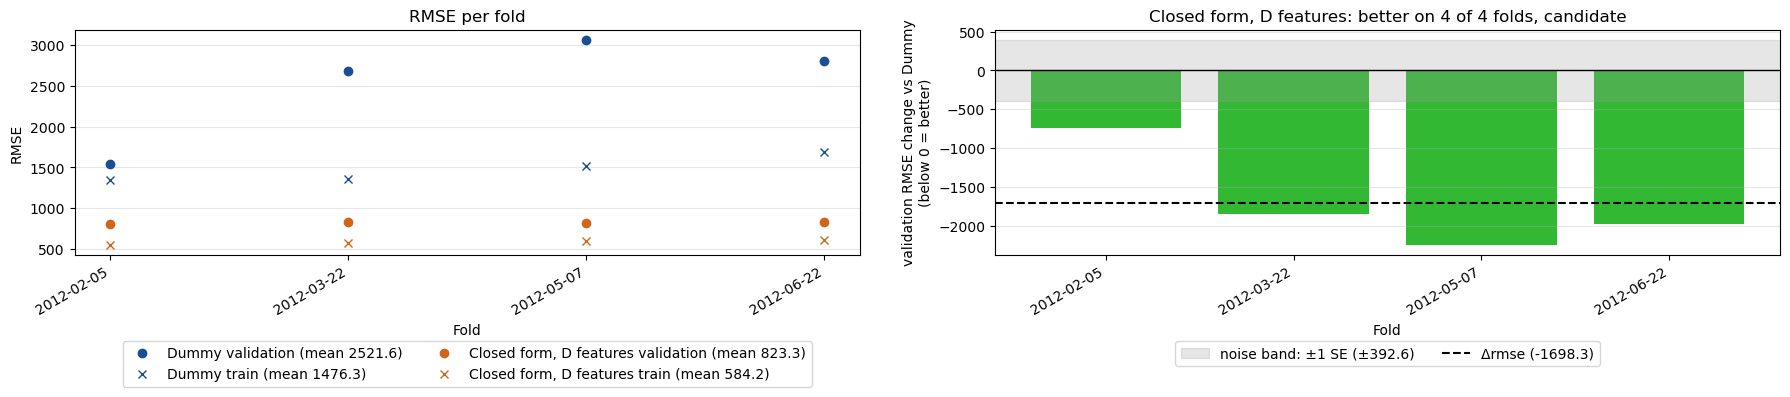

In [7]:
compare('Dummy', 'Closed form, D features')

### Notes / Observations

- D's model is the yardstick: its feature set, solved by SVD, scores 823.3, and every polynomial below is compared with it.
- The time gap is there before any polynomial: Dummy, which cannot overfit, has a training RMSE of 1476.3 against 2521.6 on validation.
- D's model carries the same kind of gap (584.2 against 823.3). Only what a polynomial adds on top of this gap counts as overfitting (see Method).

# Closed Form on Polynomial Columns

D's feature set with every column expanded, at degrees 1 to 4, solved two ways: `LinearRegression` and SVD (`PIPELINES.SVDRegression`). Both find the least squares fit; they differ in how small a singular value has to be before it counts as 0. **columns** is how many columns the model gets, and **independent columns** how many of them are not exact combinations of the others, on the training rows of fold 1.

In [8]:
for degree in DEGREES:
	score(f'LinearRegression, degree {degree}', build(LinearRegression(), D_FEATURES, degree=degree))
	score(f'SVD, degree {degree}', build(PIPELINES.SVDRegression(), D_FEATURES, degree=degree))

pd.DataFrame([
	{
		**counts(build(PIPELINES.SVDRegression(), D_FEATURES, degree=degree)),
		'LinearRegression rmse': RUNS[f'LinearRegression, degree {degree}']['validation rmse'].mean(),
		'SVD rmse': RUNS[f'SVD, degree {degree}']['validation rmse'].mean(),
		'LinearRegression highest fold': RUNS[f'LinearRegression, degree {degree}']['validation rmse'].max(),
		'SVD highest fold': RUNS[f'SVD, degree {degree}']['validation rmse'].max(),
	}
	for degree in DEGREES
], index=pd.Index(DEGREES, name='degree'))

,columns,independent columns,LinearRegression rmse,SVD rmse,LinearRegression highest fold,SVD highest fold
degree,,,,,,
1,11,11,823.3,823.3,834.6,834.6
2,77,69,2706831969991177.5,1094.9,10795767115404082.0,1753.8
3,363,221,12743802926256890.0,6387.4,35375789667486060.0,17826.7
4,1364,399,390189.6,378681.7,757219.5,714091.1


### Notes / Observations

- `LinearRegression` breaks from degree 2, SVD does not: about 3e15 at degree 2, against 1094.9 for SVD. It treats rounding noise in the repeated columns as real and predicts wildly on new days. This is a solver failure, not the model's, so SVD is the closed form from here on.
- Expanding every column repeats columns at once: 69 of the 77 columns are independent at degree 2, since a 0 / 1 column squared is the same column.
- At degree 4 both solvers fail (378681.7 by SVD).
- There, 399 independent columns meet fold 1's 400 training days, so the fit matches the training days exactly and means nothing on later days.

# Degree and Expanded Columns

Every pair of a set of expanded columns and a degree, by closed form, against D's model. Each set starts from D's carried feature set or from the 11 raw attributes, and expands more of its columns at each tier:
- **continuous:** only the continuous attributes (`FeelsLike`, `Humidity` and `Wind` in D's set, which dropped `Temp`; all four in the raw set).
- **continuous + 0/1:** the 0/1 attributes too (`Year`, `IsHoliday`, and `IsWorkday` in the raw set).
- **every column:** every column, the codes and `Season`'s groups included.

At degree 1 nothing is expanded, so the 3 tiers of a start are the same model: every `D features` tier at degree 1 is D's model, and every `Raw` tier is the closed form on the raw attributes.

## Every Pair

In [9]:
YMAX = 2700  # a little above Dummy's RMSE: a run that fails is drawn at the top of the chart instead of flattening the rest
SETS = {  # name: (shapes, the attributes whose columns are expanded, None for every column)
	'D features, continuous': (D_FEATURES, ['FeelsLike', 'Humidity', 'Wind']),
	'D features, continuous + 0/1': (D_FEATURES, ['FeelsLike', 'Humidity', 'Wind', 'Year', 'IsHoliday']),
	'D features, every column': (D_FEATURES, None),
	'Raw, continuous': (RAW, ['Temp', 'FeelsLike', 'Humidity', 'Wind']),
	'Raw, continuous + 0/1': (RAW, ['Temp', 'FeelsLike', 'Humidity', 'Wind', 'Year', 'IsHoliday', 'IsWorkday']),
	'Raw, every column': (RAW, None),
}

PAIRS = {(expanded, degree): f'{expanded}, degree {degree}' for expanded in SETS for degree in DEGREES}
for (expanded, degree), name in PAIRS.items():
	shapes, expand = SETS[expanded]
	score(name, build(PIPELINES.SVDRegression(), shapes, degree=degree, expand=expand))

COUNTS = pd.DataFrame({
	'Closed form, D features': counts(build(PIPELINES.SVDRegression(), D_FEATURES)),
	**{
		name: counts(build(PIPELINES.SVDRegression(), SETS[expanded][0], degree=degree, expand=SETS[expanded][1]))
		for (expanded, degree), name in PAIRS.items()
	},
}).T
table(list(PAIRS.values()), baseline='Closed form, D features').join(COUNTS)

,rmse,train rmse,Δrmse,SE,better folds,verdict,columns,independent columns
"Closed form, D features",823.3,584.2,NaN,NaN,,baseline,11,11
"D features, continuous, degree 1",823.3,584.2,0.0,0.0,0 of 4,within noise,11,11
"D features, continuous, degree 2",845.8,556.5,22.4,19.7,1 of 4,worse,21,20
"D features, continuous, degree 3",810.6,531.4,-12.8,34.8,3 of 4,within noise,41,36
"D features, continuous, degree 4",821.2,505.3,-2.2,36.3,2 of 4,within noise,76,61
"D features, continuous + 0/1, degree 1",823.3,584.2,0.0,0.0,0 of 4,within noise,11,11
"D features, continuous + 0/1, degree 2",821.3,535.8,-2.0,86.2,1 of 4,within noise,32,29
"D features, continuous + 0/1, degree 3",3572.0,491.5,2748.7,1748.8,0 of 4,worse,88,60
"D features, continuous + 0/1, degree 4",6033.9,448.3,5210.6,5774.8,0 of 4,within noise,214,101
"D features, every column, degree 1",823.3,584.2,0.0,0.0,0 of 4,within noise,11,11


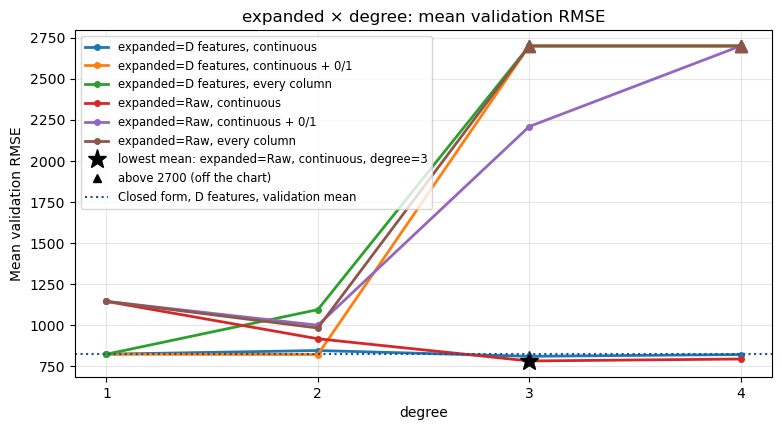

In [10]:
PLOTTING.parameter_cross(
	runs={pair: RUNS[name] for pair, name in PAIRS.items()},
	lines='expanded',
	x='degree',
	reference=('Closed form, D features', RUNS['Closed form, D features']),
	ymax=YMAX,
);

### Notes / Observations

- No pair at degree 2 or above clears 1 SE against D's model: with 4 folds the SEs are as large as the changes, so the Degree rule falls back to the lowest mean (see Carried Degree).
- Only the continuous attributes can be expanded: from degree 3, every pair that also expands the 0/1 attributes or every column is better on none of the 4 blocks, while its training RMSE keeps falling (ex `D features, every column` at degree 3: 298.2 training against 6387.4 validation). These fit the training days and miss the later ones.
- On the raw attributes, the polynomial on the 4 continuous ones does what D's shapes did: from 1144.9 at degree 1 to 782.1 at degree 3, level with D's model.
- `D features, continuous + 0/1, degree 4` reads within noise only because its SE (5774.8) is as large as its change; it is worse on all 4 blocks.
- Degree 1 is the same model in every tier of a start, since nothing is expanded, so those rows repeat by definition.

## Carried Degree

The Degree rule (see Method): of the pairs at degree 2 or above, the lowest mean among the candidates against D's model, or the lowest mean of them all when none is a candidate.

,carried
expanded,"Raw, continuous"
degree,3


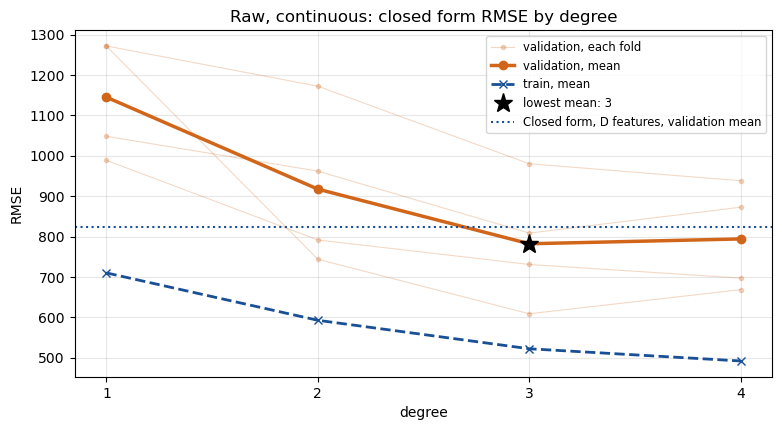

In [11]:
def carried_degree(pairs):
	"""The Degree rule: of the pairs at degree 2 or above, the one with the lowest mean among the candidates against
	D's model, or the lowest mean of them all when none is a candidate (the homework asks for polynomial regression)."""
	polynomial = {pair: name for pair, name in pairs.items() if pair[1] > 1}
	candidates = [
		pair for pair, name in polynomial.items()
		if STATISTICS.fold_difference(baseline=RUNS['Closed form, D features'], candidate=RUNS[name], folds=FOLDS).verdict == 'candidate'
	]
	return min(candidates or polynomial, key=lambda pair: RUNS[polynomial[pair]]['validation rmse'].mean())

EXPANDED, DEGREE = carried_degree(PAIRS)
STARTING_SHAPES, EXPAND = SETS[EXPANDED]
CARRIED = PAIRS[(EXPANDED, DEGREE)]
display(pd.Series({'expanded': EXPANDED, 'degree': DEGREE}, dtype=object).to_frame('carried'))

PLOTTING.parameter_search(
	runs={degree: RUNS[PAIRS[(EXPANDED, degree)]] for degree in DEGREES},
	parameter='degree',
	reference=('Closed form, D features', RUNS['Closed form, D features']),
	ymax=YMAX,
	title=f'{EXPANDED}: closed form RMSE by degree',
);

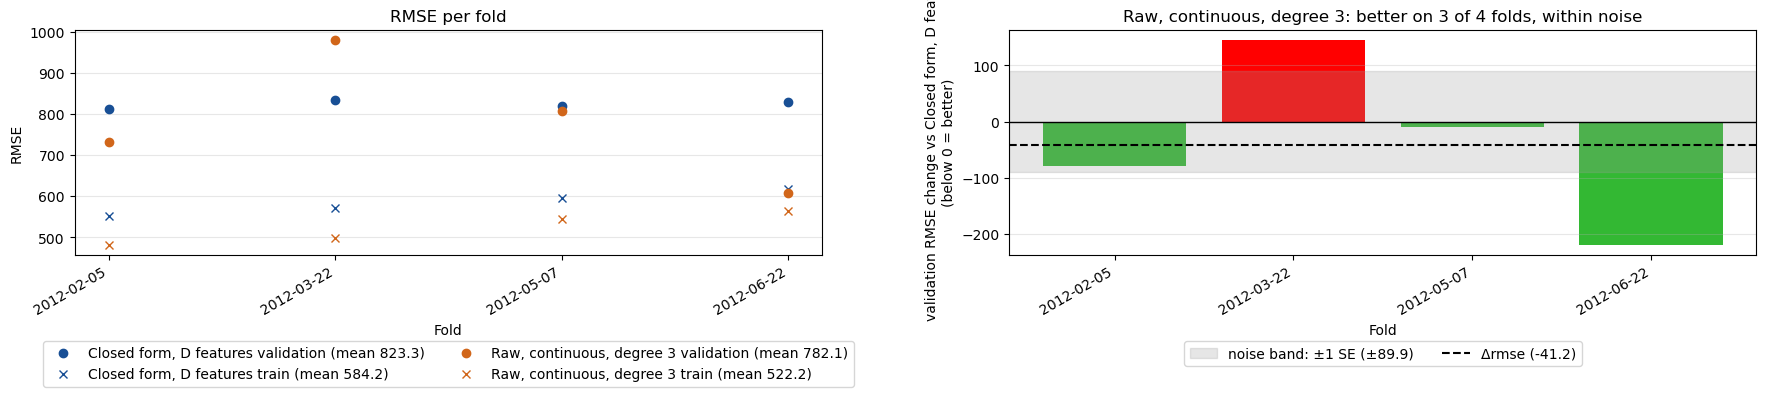

In [12]:
compare('Closed form, D features', CARRIED)

### Notes / Observations

- Carried by the forced part of the Degree rule, as a tie: the raw attributes with only the 4 continuous ones expanded, at degree 3, the lowest mean of all pairs at degree 2 or above (-41.2, SE 89.9).
- The gain does not hold on every block: the 2012-03-22 block gets worse while the 2012-06-22 block gains the most, so the SE is about twice the change.
- Degree 3 is the low point of this start: degree 4 is higher again (794.1 against 782.1) while training RMSE keeps falling, the first sign of overfitting.
- Part of the fit does not carry to later days: against D's model, training RMSE falls further (to 522.2 from 584.2) than validation RMSE does.

# Feature Shapes

The start is the carried pair: the 11 raw attributes with only the 4 continuous ones expanded, at degree 3. Each experiment changes one thing against it, from the treatments D tested for that attribute: a shape or an encoding in place of the raw attribute, an attribute's own slope in each month added, or attributes dropped.

| Attribute | In the start | Tested against it |
|---|---|---|
| `FeelsLike` | raw | cap, dropped |
| `Temp` | raw | cap, dropped |
| `Humidity` | raw | floor; hinge with the one 0.0 day clipped up |
| `Month` | the code as a number | hinge; one-hot; sine / cosine with 2 waves; its own slope of `FeelsLike` or of `Humidity` in each month |
| `Season` | the code as a number | 3 groups, one-hot, dropped |
| `Wind` | raw | windy day flag, dropped |
| `Weather` | the code as a number | dropped |
| `Weekday`, `IsWorkday`, `IsHoliday` | raw | the three dropped together |
| `Year` | raw | nothing: Q2B keeps it in every model |

Every model in this section is the closed form at degree 3, with the same attributes expanded. A shape on an expanded attribute is expanded too.

## Experiments

In [13]:
def closed_form(shapes):
	"""The closed form of shapes at the carried degree and expanded columns."""
	return build(PIPELINES.SVDRegression(), shapes, degree=DEGREE, expand=EXPAND)

EXPERIMENTS = {
	'Add: FeelsLike cap': {**STARTING_SHAPES, 'FeelsLike': shape('FeelsLike', 'cap')},
	'Add: Temp cap': {**STARTING_SHAPES, 'Temp': shape('Temp', 'cap')},
	'Add: Humidity floor': {**STARTING_SHAPES, 'Humidity': shape('Humidity', 'floor')},
	'Add: Humidity clipped hinge': {**STARTING_SHAPES, 'Humidity': HUMIDITY_CLIPPED_HINGE},
	'Add: Month hinge': {**STARTING_SHAPES, 'Month': shape('Month', 'hinge')},
	'Add: Month one-hot': {**STARTING_SHAPES, 'Month': shape('Month', 'one-hot')},
	'Add: Month sine / cosine': {**STARTING_SHAPES, 'Month': shape('Month', 'sine / cosine, 2 waves')},
	'Add: Season 3 groups': {**STARTING_SHAPES, 'Season': shape('Season', '3 groups')},
	'Add: Season one-hot': {**STARTING_SHAPES, 'Season': shape('Season', 'one-hot')},
	'Add: Wind flag': {**STARTING_SHAPES, 'Wind': shape('Wind', 'step')},
	'Add: FeelsLike by month': {**STARTING_SHAPES, 'FeelsLike by month': by_month('FeelsLike')},
	'Add: Humidity by month': {**STARTING_SHAPES, 'Humidity by month': by_month('Humidity')},
	'Drop: FeelsLike': {**STARTING_SHAPES, 'FeelsLike': 'drop'},
	'Drop: Temp': {**STARTING_SHAPES, 'Temp': 'drop'},
	'Drop: Season': {**STARTING_SHAPES, 'Season': 'drop'},
	'Drop: Wind': {**STARTING_SHAPES, 'Wind': 'drop'},
	'Drop: Weather': {**STARTING_SHAPES, 'Weather': 'drop'},
	'Drop: Weekday, IsWorkday, IsHoliday': {**STARTING_SHAPES, 'Weekday': 'drop', 'IsWorkday': 'drop', 'IsHoliday': 'drop'},
}
for name, shapes in EXPERIMENTS.items():
	score(name, closed_form(shapes))

table(list(EXPERIMENTS), baseline=CARRIED)

,rmse,train rmse,Δrmse,SE,better folds,verdict
"Raw, continuous, degree 3",782.1,522.2,NaN,NaN,,baseline
Add: FeelsLike cap,810.5,516.2,28.4,15.2,0 of 4,worse
Add: Temp cap,807.4,519.4,25.3,22.2,1 of 4,worse
Add: Humidity floor,816.8,523.4,34.7,23.0,0 of 4,worse
Add: Humidity clipped hinge,797.2,499.2,15.1,22.0,1 of 4,within noise
Add: Month hinge,755.4,502.9,-26.7,25.7,3 of 4,candidate
Add: Month one-hot,804.3,485.5,22.2,48.3,1 of 4,within noise
Add: Month sine / cosine,780.7,498.1,-1.4,47.9,1 of 4,within noise
Add: Season 3 groups,759.3,510.3,-22.8,61.4,2 of 4,within noise
Add: Season one-hot,765.2,507.3,-16.9,52.2,2 of 4,within noise


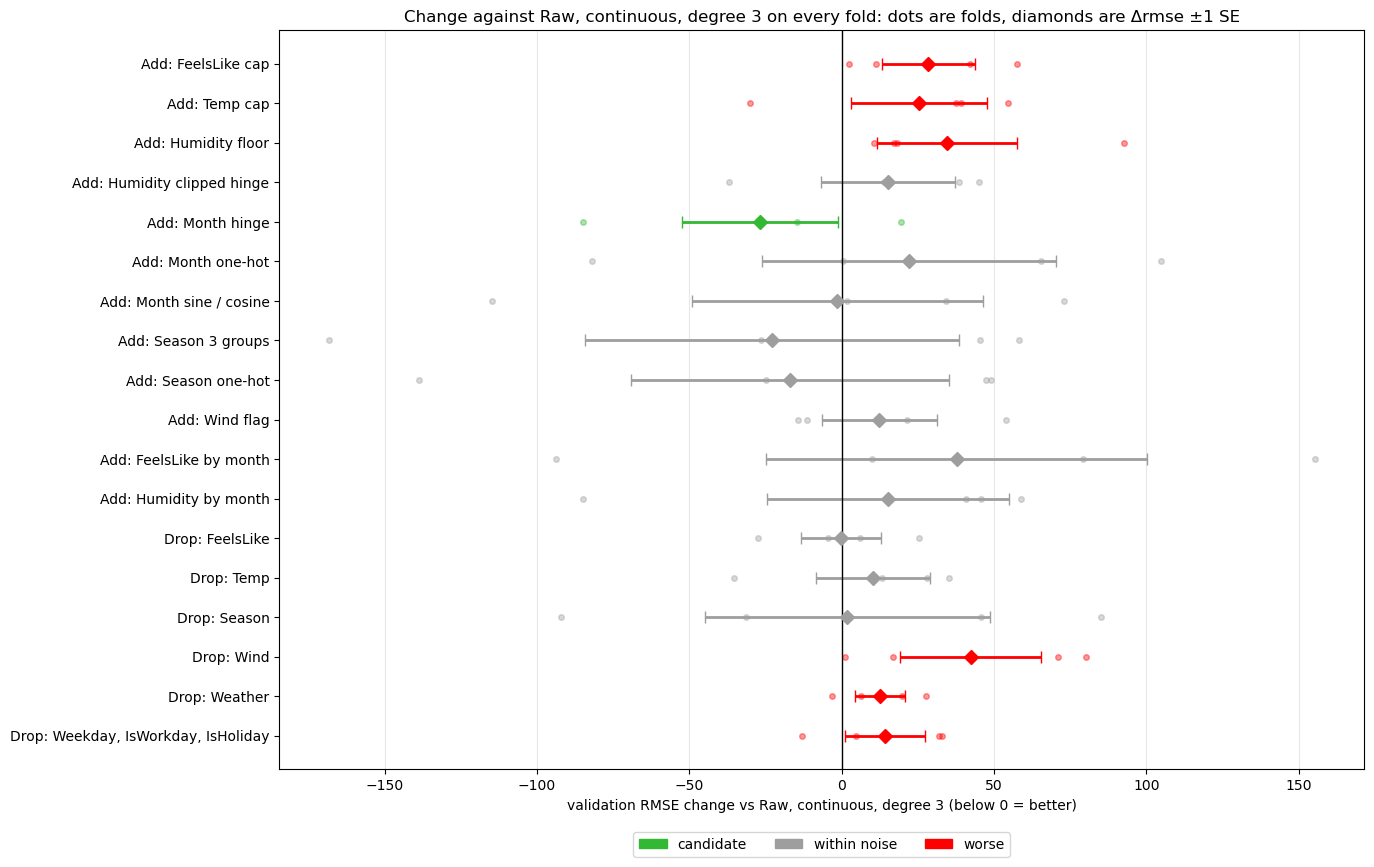

In [14]:
deltas(list(EXPERIMENTS), baseline=CARRIED)

### Notes / Observations

- Only `Month`'s hinge is a candidate (-26.7, SE 25.7): with the continuous attributes expanded, the month code still needs its bend.
- D's caps and floor now cost: on top of the degree 3 terms, each makes the fit worse (ex `FeelsLike`'s cap, +28.4).
- `Season`'s 3 groups lower the mean but with a wide SE (-22.8, SE 61.4), so within noise, and they are not taken.
- A slope per month or a `Month` one-hot fits the training days, not the later ones: `FeelsLike` by month lowers training RMSE to 482.3 while validation RMSE rises.
- `Wind`, `Weather`, and `Weekday`, `IsWorkday` and `IsHoliday` together earn their place: dropping them is worse (ex `Wind`, +42.3).
- Dropping `FeelsLike` ties (-0.2, SE 13.0), so it is left to Drop One.

## Combined

Every candidate, plus every change back to raw that is within noise (it makes the model simpler), together. A drop that is only within noise is left to Drop One, which removes one attribute at a time, so two attributes that cover for each other cannot leave together. When several rows touch the same attribute, the one with the lowest rmse wins. If Combined has a higher mean than the start, the best single change is carried instead.

In [15]:
COMBINED = {
	**STARTING_SHAPES,
	'Month': shape('Month', 'hinge'),  # the only candidate
}  # every attribute starts raw, so no change goes back to raw; the drops within noise are left to Drop One
score('Combined', closed_form(COMBINED))

table(['Combined'], baseline=CARRIED)

,rmse,train rmse,Δrmse,SE,better folds,verdict
"Raw, continuous, degree 3",782.1,522.2,NaN,NaN,,baseline
Combined,755.4,502.9,-26.7,25.7,3 of 4,candidate


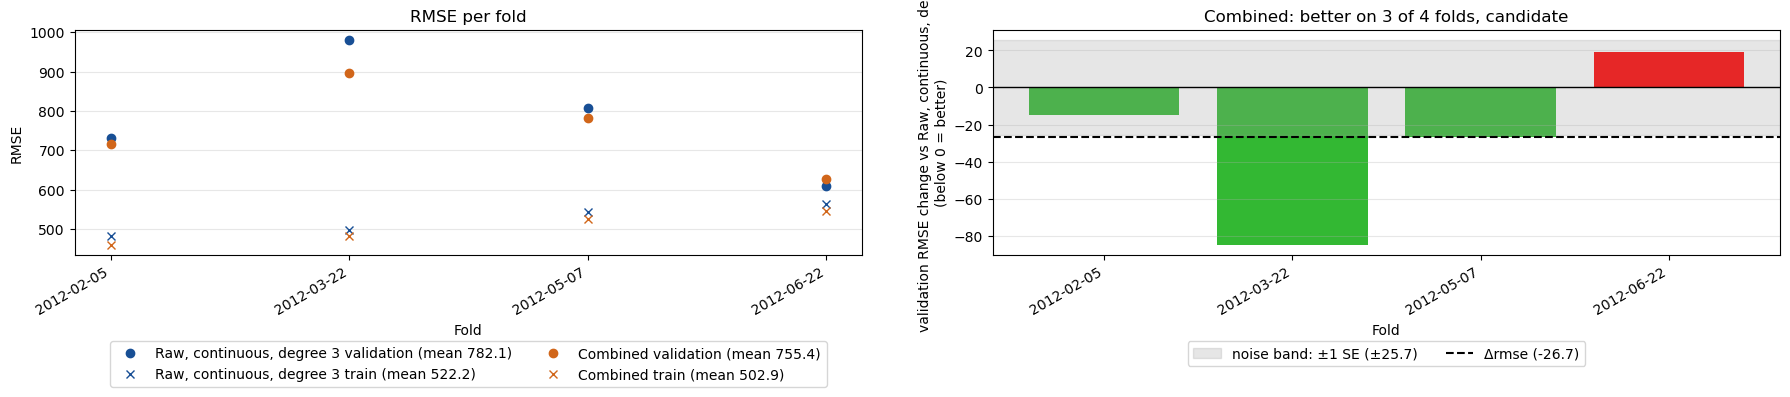

In [16]:
compare(CARRIED, 'Combined')

### Notes / Observations

- Combined is the one candidate, so it is the same model as `Add: Month hinge` (755.4).
- The gain sits on the 2012-03-22 block; the 2012-06-22 block is slightly worse.

# Drop One

Every attribute left in the model has to earn its place: dropping it must raise the mean validation RMSE. Each round drops every remaining attribute one at a time. When some drops do not raise the mean, the cheapest of them (the lowest rmse once dropped) first gets its other Q2B shapes, and one that beats the drop on the mean earns the attribute its place. Otherwise the attribute is dropped and the next round starts from the smaller model, so two attributes that cover for each other cannot leave together. The rounds end when every drop raises the mean.

The mean is used here, not the 1 SE rule: the 1 SE rule asks whether a change is real, while Drop One only asks whether the model is better with the attribute or without it. With only 4 time-ordered folds, the SE is too wide to confirm a cost the model really pays, and the rounds would strip attributes it needs.

In [17]:
def drop_one(shapes, prefix):
	"""Score the closed form of shapes with each attribute still in it dropped, one at a time, and return the run names."""
	names = []
	for attribute in ATTRIBUTES:
		if shapes.get(attribute) != 'drop':
			name = f'{prefix}: drop {attribute}'
			score(name, closed_form({**shapes, attribute: 'drop'}))
			names.append(name)
	return names

## Round 1

In [18]:
ROUND_1 = drop_one(COMBINED, 'Round 1')

table(ROUND_1, baseline='Combined')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Combined,755.4,502.9,NaN,NaN,,baseline
Round 1: drop Temp,758.2,524.2,2.8,11.1,1 of 4,within noise
Round 1: drop FeelsLike,749.9,517.0,-5.4,8.3,3 of 4,within noise
Round 1: drop Humidity,805.9,551.6,50.5,7.5,0 of 4,worse
Round 1: drop Wind,793.9,558.1,38.5,12.5,0 of 4,worse
Round 1: drop Year,1828.2,752.0,1072.9,140.0,0 of 4,worse
Round 1: drop IsHoliday,751.6,508.2,-3.8,5.0,2 of 4,within noise
Round 1: drop IsWorkday,753.6,503.0,-1.8,1.6,4 of 4,candidate
Round 1: drop Season,765.4,530.4,10.0,34.9,1 of 4,within noise
Round 1: drop Month,778.5,522.5,23.2,26.8,1 of 4,within noise


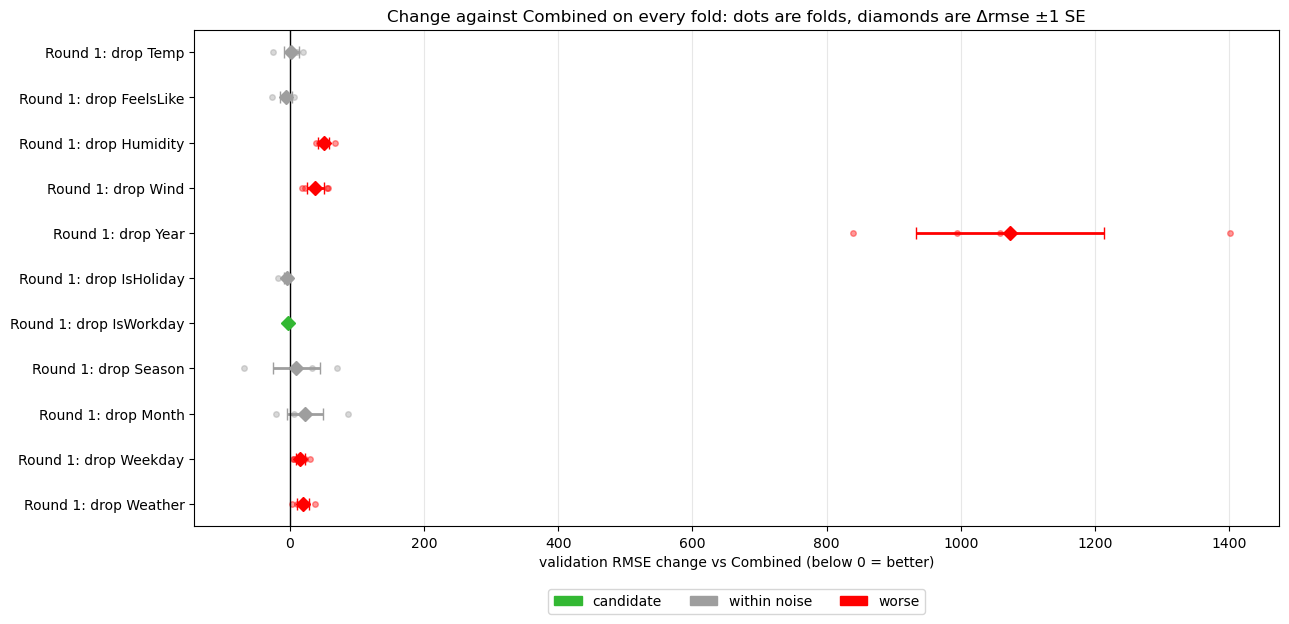

In [19]:
deltas(ROUND_1, baseline='Combined')

### Notes / Observations

- Three drops do not raise the mean: `FeelsLike`, `IsHoliday` and `IsWorkday`. `FeelsLike` gives the lowest (749.9), so it is the one tried this round.
- `IsWorkday` reads candidate on a tiny change (-1.8, SE 1.6): the change is almost the same on every block, so its SE is small too. It is not the drop taken: the rule takes the lowest mean, one attribute per round, and tests the rest again in the next round.
- `Year` carries the model: dropping it costs +1072.9.

### FeelsLike

Of the drops that do not raise the mean validation RMSE, dropping `FeelsLike` gives the lowest. Its other Q2B shape, the cap, gets its chance first: if it beats the drop on the mean, `FeelsLike` stays with it.

In [20]:
score('Round 1: FeelsLike cap', closed_form({**COMBINED, 'FeelsLike': shape('FeelsLike', 'cap')}))

table(['Round 1: FeelsLike cap'], baseline='Round 1: drop FeelsLike')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Round 1: drop FeelsLike,749.9,517.0,NaN,NaN,,baseline
Round 1: FeelsLike cap,773.2,496.4,23.3,20.7,1 of 4,worse


### Notes / Observations

- The cap does worse than dropping `FeelsLike` (+23.3, SE 20.7), so `FeelsLike` is dropped and `Temp` alone carries the temperature.

## Round 2

In [21]:
AFTER_ROUND_1 = {**COMBINED, 'FeelsLike': 'drop'}  # the cap does not beat the drop, so FeelsLike is dropped
score('After round 1', closed_form(AFTER_ROUND_1))
ROUND_2 = drop_one(AFTER_ROUND_1, 'Round 2')

table(ROUND_2, baseline='After round 1')

,rmse,train rmse,Δrmse,SE,better folds,verdict
After round 1,749.9,517.0,NaN,NaN,,baseline
Round 2: drop Temp,1021.7,686.8,271.7,45.7,0 of 4,worse
Round 2: drop Humidity,805.3,574.2,55.3,10.7,0 of 4,worse
Round 2: drop Wind,797.1,571.2,47.2,14.8,0 of 4,worse
Round 2: drop Year,1804.6,765.6,1054.6,144.2,0 of 4,worse
Round 2: drop IsHoliday,748.5,521.3,-1.4,5.0,1 of 4,within noise
Round 2: drop IsWorkday,748.6,517.1,-1.3,1.1,2 of 4,candidate
Round 2: drop Season,763.8,544.2,13.8,29.7,1 of 4,within noise
Round 2: drop Month,778.7,539.3,28.8,28.0,1 of 4,worse
Round 2: drop Weekday,765.3,523.8,15.4,7.5,0 of 4,worse


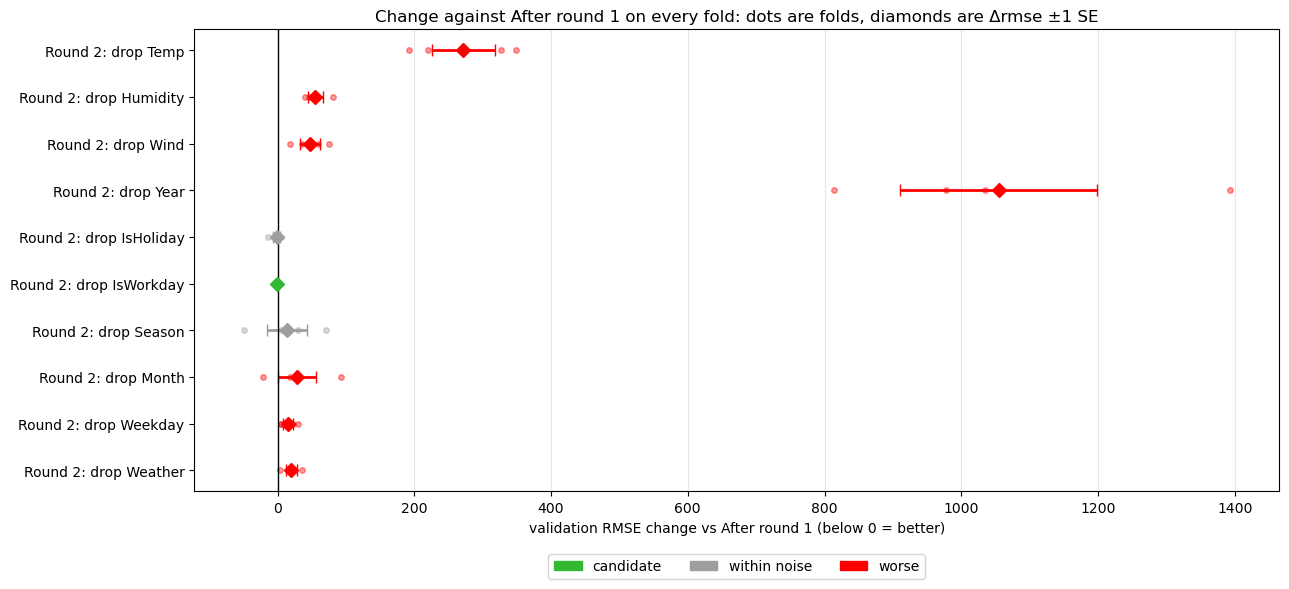

In [22]:
deltas(ROUND_2, baseline='After round 1')

### Notes / Observations

- `Temp` and `FeelsLike` covered for each other: with `FeelsLike` gone, dropping `Temp` costs +271.7, against +2.8 in round 1. This is why Drop One removes one attribute per round.
- `IsHoliday` (748.5) edges `IsWorkday` (748.6), so `IsHoliday` goes this round. `IsWorkday` again reads candidate on a tiny, steady change, and is tested again next round.

### IsHoliday

Of the drops that do not raise the mean validation RMSE, dropping `IsHoliday` gives the lowest. It is one 0/1 column, so it has no other Q2B shape to try, and it is dropped.

## Round 3

In [23]:
AFTER_ROUND_2 = {**AFTER_ROUND_1, 'IsHoliday': 'drop'}
score('After round 2', closed_form(AFTER_ROUND_2))
ROUND_3 = drop_one(AFTER_ROUND_2, 'Round 3')

table(ROUND_3, baseline='After round 2')

,rmse,train rmse,Δrmse,SE,better folds,verdict
After round 2,748.5,521.3,NaN,NaN,,baseline
Round 3: drop Temp,1020.1,689.7,271.6,46.7,0 of 4,worse
Round 3: drop Humidity,804.8,576.0,56.3,11.7,0 of 4,worse
Round 3: drop Wind,796.2,574.4,47.7,14.5,0 of 4,worse
Round 3: drop Year,1804.9,767.6,1056.3,148.1,0 of 4,worse
Round 3: drop IsWorkday,747.7,521.7,-0.9,2.2,1 of 4,within noise
Round 3: drop Season,762.3,548.8,13.7,31.0,1 of 4,within noise
Round 3: drop Month,779.2,544.6,30.7,31.0,1 of 4,within noise
Round 3: drop Weekday,764.5,529.2,16.0,8.8,0 of 4,worse
Round 3: drop Weather,767.3,536.6,18.8,8.8,0 of 4,worse


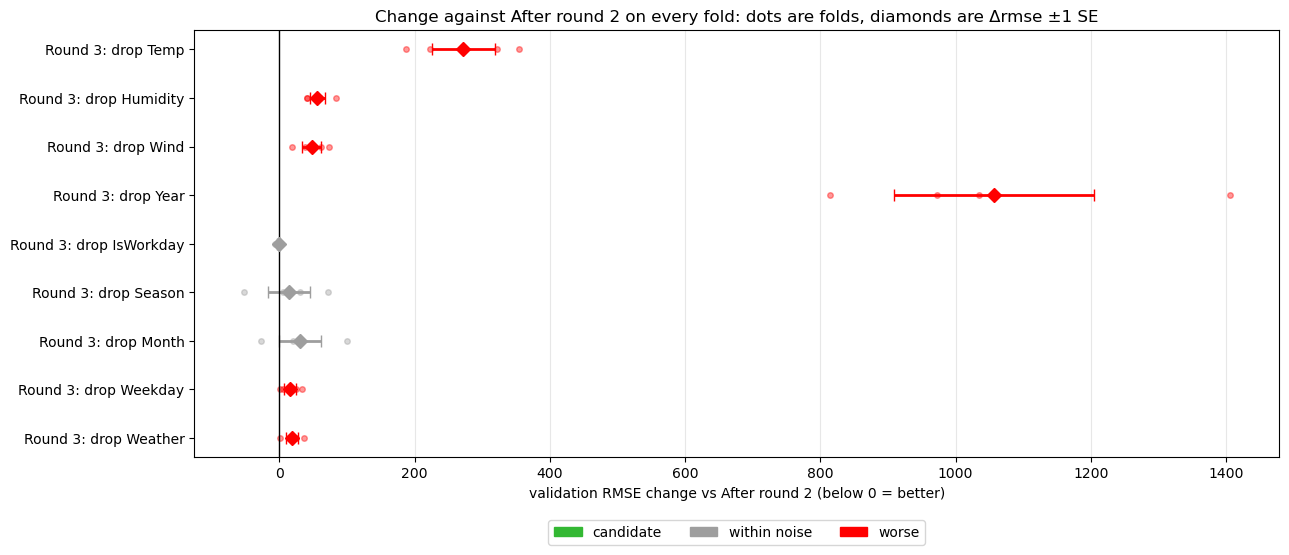

In [24]:
deltas(ROUND_3, baseline='After round 2')

### Notes / Observations

- Only `IsWorkday`'s drop does not raise the mean (-0.9, SE 2.2), so it is dropped. With `IsHoliday` gone, it no longer reads candidate.
- `Month` stays on the mean, not on the 1 SE rule: its drop costs +30.7, about 1 SE (31.0).

### IsWorkday

Of the drops that do not raise the mean validation RMSE, dropping `IsWorkday` gives the lowest. It is one 0/1 column, so it has no other Q2B shape to try, and it is dropped.

## Round 4

In [25]:
FEATURES = {**AFTER_ROUND_2, 'IsWorkday': 'drop'}
score('Closed form, features', closed_form(FEATURES))
ROUND_4 = drop_one(FEATURES, 'Round 4')

table(ROUND_4, baseline='Closed form, features')

,rmse,train rmse,Δrmse,SE,better folds,verdict
"Closed form, features",747.7,521.7,NaN,NaN,,baseline
Round 4: drop Temp,1019.8,692.5,272.1,52.2,0 of 4,worse
Round 4: drop Humidity,804.9,577.3,57.3,11.4,0 of 4,worse
Round 4: drop Wind,795.4,575.3,47.7,14.5,0 of 4,worse
Round 4: drop Year,1804.6,767.7,1056.9,147.5,0 of 4,worse
Round 4: drop Season,761.3,549.2,13.6,30.9,1 of 4,within noise
Round 4: drop Month,778.2,544.8,30.6,31.1,1 of 4,within noise
Round 4: drop Weekday,764.0,529.7,16.3,8.6,0 of 4,worse
Round 4: drop Weather,766.1,536.8,18.4,9.9,1 of 4,worse


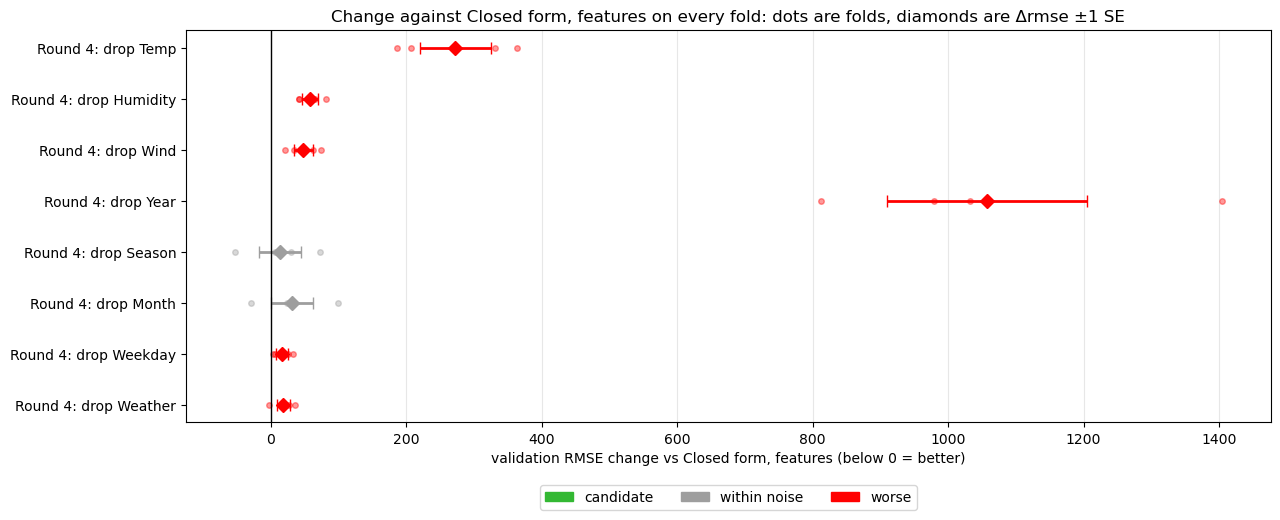

In [26]:
deltas(ROUND_4, baseline='Closed form, features')

### Notes / Observations

- The rounds end: every drop raises the mean. The closest call is `Season` (+13.6, SE 30.9).
- The carried feature set: 8 attributes, `Temp`, `Humidity` and `Wind` raw and expanded at degree 3, `Month` with a hinge, `Year`, `Season`, `Weekday` and `Weather` raw. `FeelsLike`, `IsHoliday` and `IsWorkday` are out.

# Carried Feature Set

The feature set and degree every model from here on uses, against D's model.

In [27]:
CLOSED_FORM = 'Closed form, features'  # the carried closed form, the one SGD is compared against

table([CLOSED_FORM], baseline='Closed form, D features')

,rmse,train rmse,Δrmse,SE,better folds,verdict
"Closed form, D features",823.3,584.2,NaN,NaN,,baseline
"Closed form, features",747.7,521.7,-75.7,67.2,3 of 4,candidate


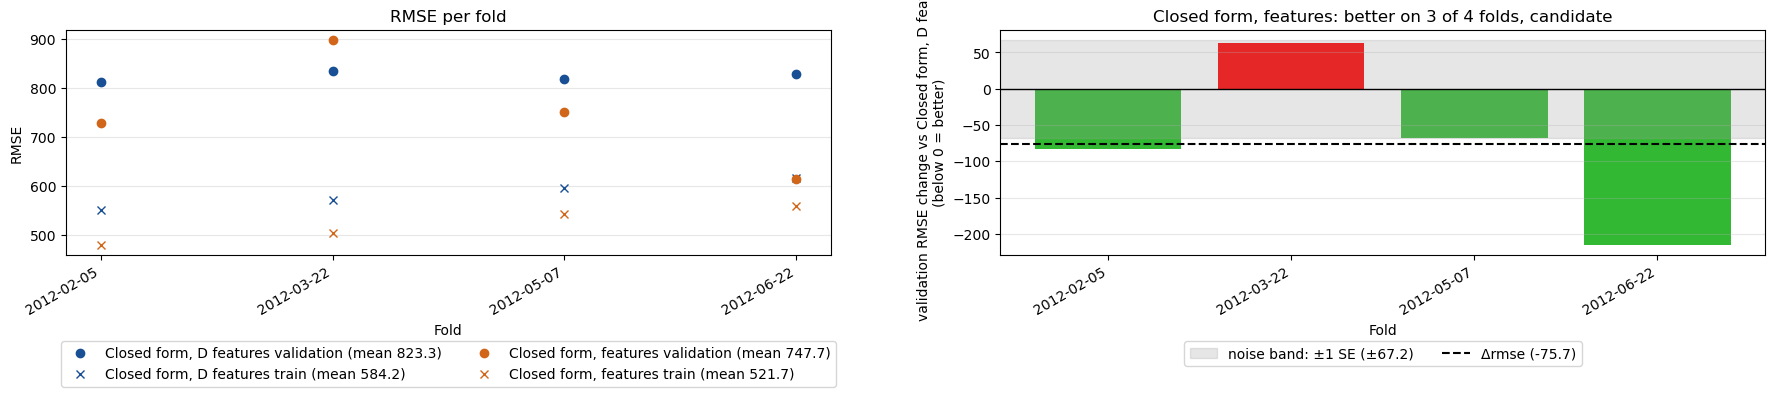

In [28]:
compare('Closed form, D features', CLOSED_FORM)

### Notes / Observations

- The polynomial now beats D's model by more than 1 SE (-75.7, SE 67.2): the degree 3 pair carried as a tie becomes a real gain once the ladder has run.
- The gain is not on every block: the 2012-06-22 block gains the most, while the 2012-03-22 block is worse.
- The gain is on the later days, not a closer fit to the training days: training RMSE falls by less than validation RMSE does (to 521.7).

# SGD

`SGDRegressor` on the carried feature set, at the carried degree. As in D, the search starts from scikit-learn's defaults. Every setting is written out, none left to a default: `penalty=None` (the default is a light L2 penalty), the learning rate schedule, `eta0`, `power_t`, `max_iter` and `tol`. `max_iter` is only a ceiling: a fit stops once its training loss improves by less than `tol` for 5 epochs in a row.

In [29]:
SGD_SETTINGS = dict(
	penalty=None,
	learning_rate='invscaling',  # step = eta0 / t ** power_t, shrinking as training goes on
	eta0=0.01,
	power_t=0.25,
	average=False,
	max_iter=MAX_ITER,
	tol=1e-3,
	random_state=SEED,
)
SETTINGS = {}  # the settings of every SGD run, keyed by name

def sgd(name, settings, degree=None):
	"""Cross validate SGD with these settings on the carried feature set, at degree (the carried degree when omitted),
	and keep the settings under name."""
	SETTINGS[name] = settings
	pipeline = build(SGDRegressor(**settings), FEATURES, degree=DEGREE if degree is None else degree, expand=EXPAND)
	score(name, pipeline)

def sweep(parameter, values, settings, baseline, prefix='', log_x=False):
	"""Cross validate SGD at each value of one parameter, the others at settings, and show the table and the chart
	against baseline. Return the run names, keyed by value."""
	names = {value: f'{prefix}{parameter}={value}' for value in values}
	for value, name in names.items():
		sgd(name, {**settings, parameter: value})
	display(table(list(names.values()), baseline=baseline))
	PLOTTING.parameter_search(
		runs={value: RUNS[name] for value, name in names.items()},
		parameter=parameter,
		log_x=log_x,
		reference=(baseline, RUNS[baseline]),
		ymax=YMAX,
		title=f'{prefix}{parameter}: RMSE on every fold',
	)
	return names

def cross(first, first_values, second, second_values, settings, baseline=None, prefix='', log_x=False):
	"""Cross validate SGD at every pair of values of two parameters, the others at settings, and show the table and the
	chart against baseline (the run at the current pair when omitted). Return the run names, keyed by pair. log_x
	applies to second."""
	names = {(a, b): f'{prefix}{first}={a}, {second}={b}' for a in first_values for b in second_values}
	for (a, b), name in names.items():
		sgd(name, {**settings, first: a, second: b})
	if baseline is None:
		baseline = names[(settings[first], settings[second])]
	display(table([name for name in names.values() if name != baseline], baseline=baseline))
	PLOTTING.parameter_cross(
		runs={pair: RUNS[name] for pair, name in names.items()},
		lines=first,
		x=second,
		log_x=log_x,
		reference=None if baseline in names.values() else (baseline, RUNS[baseline]),
		ymax=YMAX,
	)
	return names

def carried(names, current):
	"""The carry rule: of the runs in names (keyed by value) that are candidates against the run at current, the value
	with the lowest mean, or current when none is."""
	candidates = [
		value for value, name in names.items()
		if STATISTICS.fold_difference(baseline=RUNS[names[current]], candidate=RUNS[name], folds=FOLDS).verdict == 'candidate'
	]
	return min(candidates, key=lambda value: RUNS[names[value]]['validation rmse'].mean(), default=current)

## SGD vs Closed Form

In [30]:
sgd('SGD', SGD_SETTINGS)

table(['SGD'], baseline=CLOSED_FORM)

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"Closed form, features",747.7,521.7,NaN,NaN,,baseline,<NA>
SGD,824.1,549.2,76.4,29.6,0 of 4,worse,21


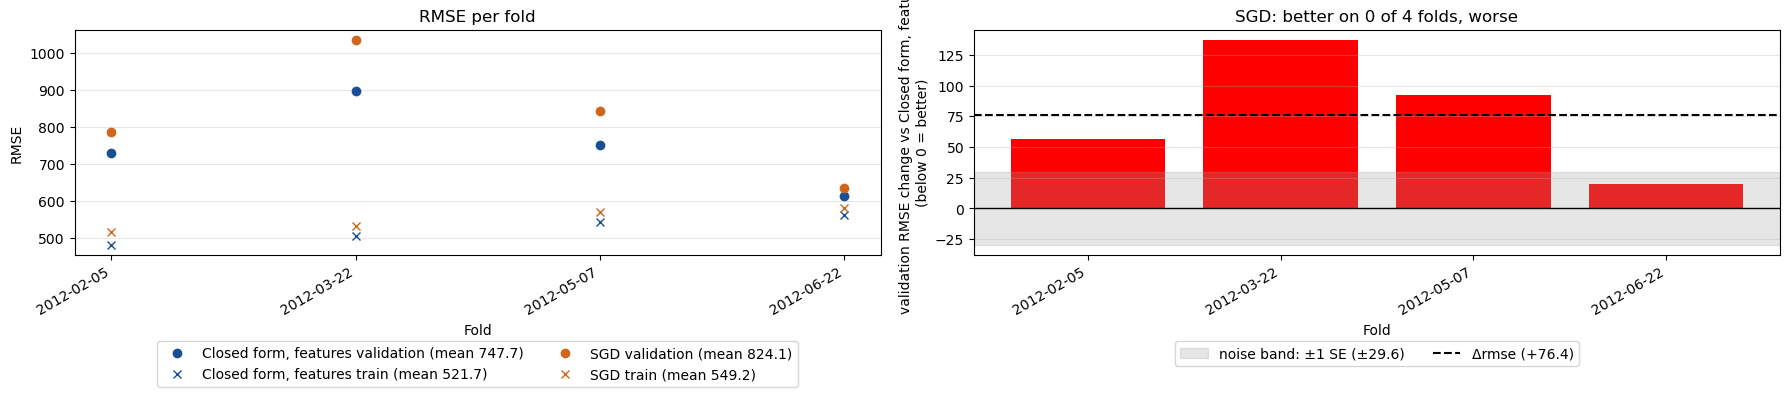

In [31]:
compare(CLOSED_FORM, 'SGD')

### Notes / Observations

- At scikit-learn's defaults, SGD stops short of the closed form at degree 3: worse on all 4 blocks (+76.4, SE 29.6).

## Hyperparameter Search

The degree is searched first, together with the starting step `eta0`, since a polynomial with more columns can need a smaller step. Then the learning rate schedule and `eta0` together at the carried degree, every pair of the 4 schedules and 6 steps, since a schedule only sets how the step changes from `eta0`. Then the stopping tolerance `tol`. Each table compares every value against the current settings (its baseline row), and a value replaces them only when it is a candidate. Of several candidates, the lowest mean wins.

### Degree × eta0

Degrees 1 to 4 with every starting step, the other settings at scikit-learn's defaults. A higher degree has more columns, and cubes and fourth powers of standardized columns have long tails, which can need a smaller step. SGD's early stop can also hide overfitting the closed form shows. As in Degree and Expanded Columns, only degrees 2 and above can be carried.

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"degree=3, eta0=0.01",824.1,549.2,NaN,NaN,,baseline,21
"degree=1, eta0=1e-05",2514.2,1468.9,1690.2,394.8,0 of 4,worse,7
"degree=1, eta0=0.0001",2012.4,1084.3,1188.4,196.7,0 of 4,worse,112
"degree=1, eta0=0.001",1310.9,737.4,486.8,61.9,0 of 4,worse,41
"degree=1, eta0=0.01",1133.4,699.9,309.3,126.4,0 of 4,worse,11
"degree=1, eta0=0.1",1117.8,700.2,293.7,155.1,0 of 4,worse,18
"degree=1, eta0=1",1088.8,851.1,264.8,139.1,0 of 4,worse,56
"degree=2, eta0=1e-05",2514.3,1467.6,1690.2,395.2,0 of 4,worse,7
"degree=2, eta0=0.0001",2003.7,1028.5,1179.6,169.9,0 of 4,worse,116
"degree=2, eta0=0.001",1169.2,651.6,345.1,61.6,0 of 4,worse,43


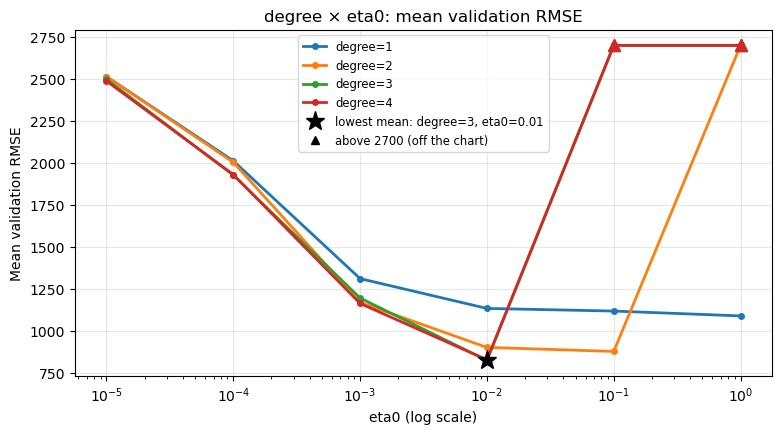

In [32]:
names = {(degree, eta0): f'degree={degree}, eta0={eta0}' for degree in DEGREES for eta0 in ETA0S}
for (degree, eta0), name in names.items():
	sgd(name, {**SGD_SETTINGS, 'eta0': eta0}, degree=degree)
baseline = names[(DEGREE, SGD_SETTINGS['eta0'])]
display(table([name for name in names.values() if name != baseline], baseline=baseline))
PLOTTING.parameter_cross(runs={pair: RUNS[name] for pair, name in names.items()}, lines='degree', x='eta0', log_x=True, ymax=YMAX)

polynomial = {pair: name for pair, name in names.items() if pair[0] > 1}  # degree 1 is not polynomial regression
DEGREE, eta0 = carried(polynomial, (DEGREE, SGD_SETTINGS['eta0']))
SGD_SETTINGS = {**SGD_SETTINGS, 'eta0': eta0}

### Notes / Observations

- No pair beats degree 3 at the default step by 1 SE, so degree 3 and `eta0` 0.01 stay. The closest is degree 4 at 0.01 (+3.4, SE 22.1).
- Degree 1 is worse than the baseline at every step (its best is 1088.8), so SGD confirms the polynomial terms help.
- The step that works shrinks as the degree grows: `eta0` 1 diverges from degree 2 on, and 0.1 from degree 3.
- `degree=3, eta0=0.1` reads within noise only because its SE (416507.7) is larger than its change; it is better on none of the 4 blocks.

### Learning Rate Schedule × eta0 (Starting Step Size)

At the carried degree. `optimal` sets its own step from `alpha` and ignores `eta0`, so its 6 rows are the same model.

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"learning_rate=invscaling, eta0=0.01",824.1,549.2,NaN,NaN,,baseline,21
"learning_rate=constant, eta0=1e-05",1817.9,925.6,993.9,169.5,0 of 4,worse,111
"learning_rate=constant, eta0=0.0001",1175.9,688.2,351.8,65.8,0 of 4,worse,46
"learning_rate=constant, eta0=0.001",832.2,554.5,8.1,9.4,2 of 4,within noise,28
"learning_rate=constant, eta0=0.01",1583.7,1857.5,759.6,594.5,1 of 4,worse,12
"learning_rate=constant, eta0=0.1",1578973240274457.0,1934464961844307.2,1578973240273632.8,390505429345524.8,0 of 4,worse,6
"learning_rate=constant, eta0=1",22039627208270424.0,30995288794225608.0,22039627208269600.0,2616134919593516.5,0 of 4,worse,10
"learning_rate=optimal, eta0=1e-05",16666843779717856.0,14881123211187732.0,16666843779717030.0,10572424907612898.0,0 of 4,worse,71
"learning_rate=optimal, eta0=0.0001",16666843779717856.0,14881123211187732.0,16666843779717030.0,10572424907612898.0,0 of 4,worse,71
"learning_rate=optimal, eta0=0.001",16666843779717856.0,14881123211187732.0,16666843779717030.0,10572424907612898.0,0 of 4,worse,71


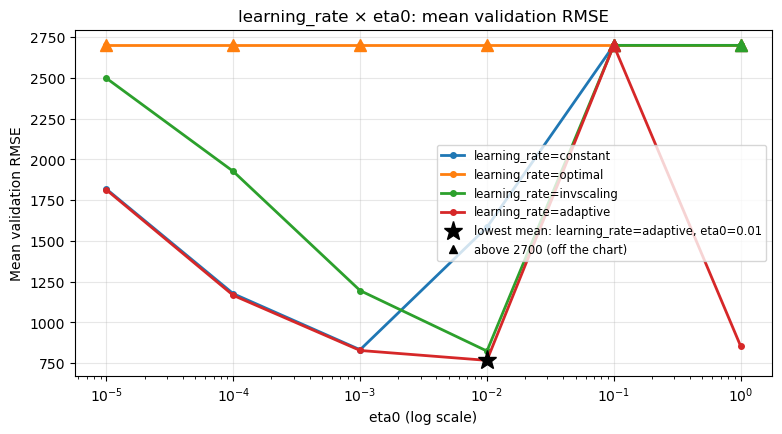

In [33]:
names = cross('learning_rate', LEARNING_RATE_SCHEDULES, 'eta0', ETA0S, SGD_SETTINGS, log_x=True)
learning_rate, eta0 = carried(names, (SGD_SETTINGS['learning_rate'], SGD_SETTINGS['eta0']))
SGD_SETTINGS = {**SGD_SETTINGS, 'learning_rate': learning_rate, 'eta0': eta0}

### Notes / Observations

- Only `adaptive` at `eta0` 0.01 is a candidate, and it is carried: -57.2 (SE 17.4).
- It cuts the step when the training loss stalls, so it trains longer (54 epochs against 21).
- `invscaling` at 0.1 reads within noise only because its SE is as large as its change; it diverges and is better on none of the 4 blocks.

### Stopping Tolerance (tol)

A fit stops once its training loss improves by less than `tol` for 5 epochs in a row, so a smaller `tol` trains longer. The loss is measured on the standardized target, so `tol` means the same in Q1 and Q2. This is the cross validated view of more epochs: if validation RMSE rises as `tol` shrinks, training longer overfits.

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
tol=0.001,766.9,525.5,NaN,NaN,,baseline,54
tol=0.01,783.3,529.8,16.4,16.9,1 of 4,within noise,44
tol=0.0001,766.4,524.9,-0.5,0.5,3 of 4,within noise,61
tol=1e-05,761.9,523.9,-5.0,6.1,2 of 4,within noise,102
tol=1e-06,757.6,523.4,-9.3,10.8,3 of 4,within noise,210


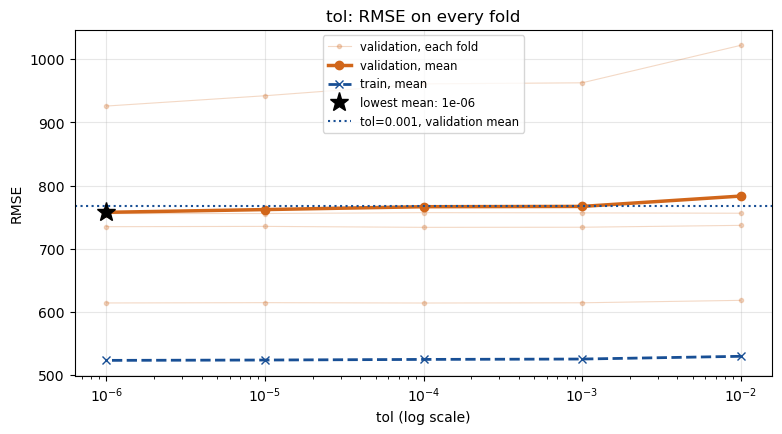

In [34]:
names = sweep('tol', TOLS, SGD_SETTINGS, baseline=f"tol={SGD_SETTINGS['tol']}", log_x=True)
SGD_SETTINGS = {**SGD_SETTINGS, 'tol': carried(names, SGD_SETTINGS['tol'])}

### Notes / Observations

- No `tol` beats 0.001 by 1 SE, so it stays. Training longer lowers the mean a little, within noise (0.000001: -9.3, SE 10.8).
- `tol` 0.0001 sits right at the 1 SE line on a steady change of 0.5 rentals (SE 0.5): too small to matter.
- Validation RMSE does not rise as `tol` shrinks, so more epochs do not overfit here.

## Tuned SGD vs Closed Form

In [35]:
sgd('SGD, tuned', SGD_SETTINGS)
display(pd.Series({**SGD_SETTINGS, 'degree': DEGREE}, name='carried').astype(str).to_frame())  # as text: the float format would round a small tol to 0

table(['SGD, tuned'], baseline=CLOSED_FORM)

,carried
penalty,None
learning_rate,adaptive
eta0,0.01
power_t,0.25
average,False
max_iter,10000
tol,0.001
random_state,42
degree,3


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"Closed form, features",747.7,521.7,NaN,NaN,,baseline,<NA>
"SGD, tuned",766.9,525.5,19.2,18.0,0 of 4,worse,54


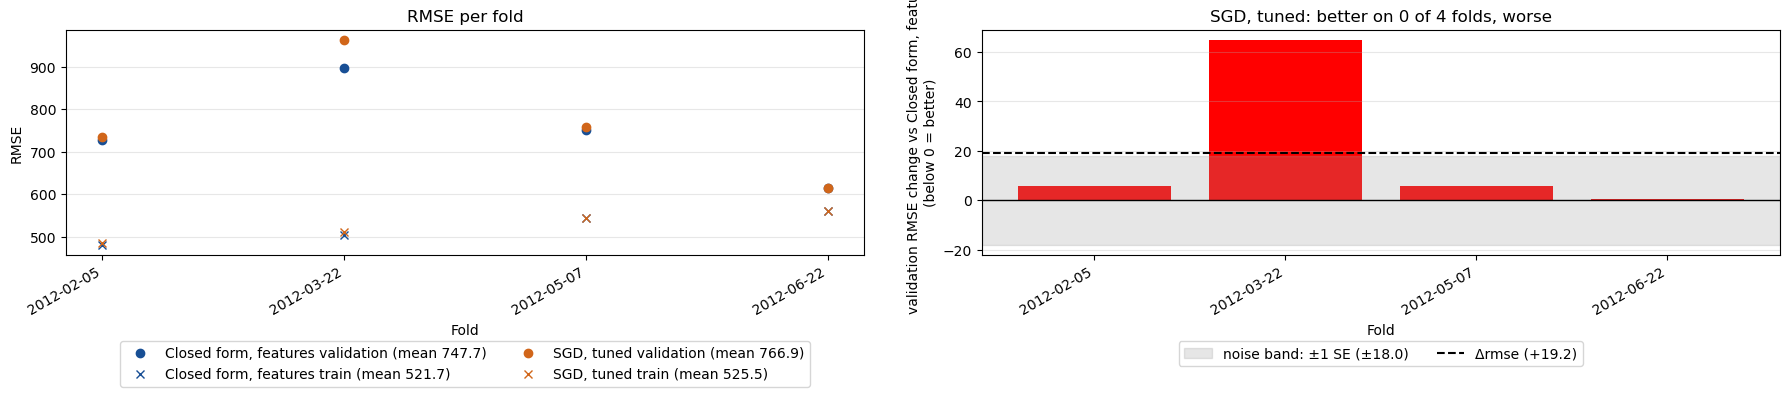

In [36]:
compare(CLOSED_FORM, 'SGD, tuned')

### Notes / Observations

- Tuned SGD still stops short of the closed form (+19.2, SE 18.0): most of the gap is on the 2012-03-22 block, and the 2012-06-22 block is about even.
- SGD fits the training days about as well as the closed form (training RMSE 525.5 against 521.7); the shortfall is on the later days.

# Regularization

The tuned SGD, at the carried degree, with a penalty: Ridge (`l2`), Lasso (`l1`) and Elastic Net (`elasticnet`, a mix of both), each against the tuned SGD with no penalty. `alpha`, the penalty's strength, is tried at 8 values from 0.000001 to 10. Elastic Net also has `l1_ratio`, its share of L1 in the penalty, so it is searched over every pair of `alpha` and `l1_ratio`, as scikit-learn's `ElasticNetCV` does. SGD's `alpha` is not the same scale as `Ridge`'s: for L2, `Ridge(alpha=n * a)` matches `SGDRegressor(alpha=a)` on n rows.

## Ridge and Lasso

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",766.9,525.5,NaN,NaN,,baseline,54
"Ridge, alpha=1e-06",766.9,525.5,0.0,0.0,0 of 4,worse,54
"Ridge, alpha=1e-05",766.9,525.5,0.0,0.0,0 of 4,worse,54
"Ridge, alpha=0.0001",767.1,525.5,0.2,0.1,0 of 4,worse,54
"Ridge, alpha=0.001",768.6,525.6,1.7,0.6,0 of 4,worse,54
"Ridge, alpha=0.01",792.9,529.6,26.0,11.9,0 of 4,worse,47
"Ridge, alpha=0.1",980.5,591.2,213.6,51.0,0 of 4,worse,47
"Ridge, alpha=1",1665.9,865.0,899.0,164.7,0 of 4,worse,47
"Ridge, alpha=10",2337.9,1285.5,1571.0,315.9,0 of 4,worse,52


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",766.9,525.5,NaN,NaN,,baseline,54
"Lasso, alpha=1e-06",766.9,525.5,0.0,0.0,1 of 4,within noise,54
"Lasso, alpha=1e-05",766.9,525.4,0.0,0.0,1 of 4,within noise,54
"Lasso, alpha=0.0001",774.3,526.8,7.4,9.4,2 of 4,within noise,49
"Lasso, alpha=0.001",776.4,526.7,9.5,7.8,2 of 4,worse,51
"Lasso, alpha=0.01",823.8,542.8,56.9,19.2,0 of 4,worse,49
"Lasso, alpha=0.1",1371.0,763.2,604.1,122.7,0 of 4,worse,46
"Lasso, alpha=1",2519.8,1476.3,1752.9,400.3,0 of 4,worse,38
"Lasso, alpha=10",2520.9,1476.3,1754.0,400.9,0 of 4,worse,38


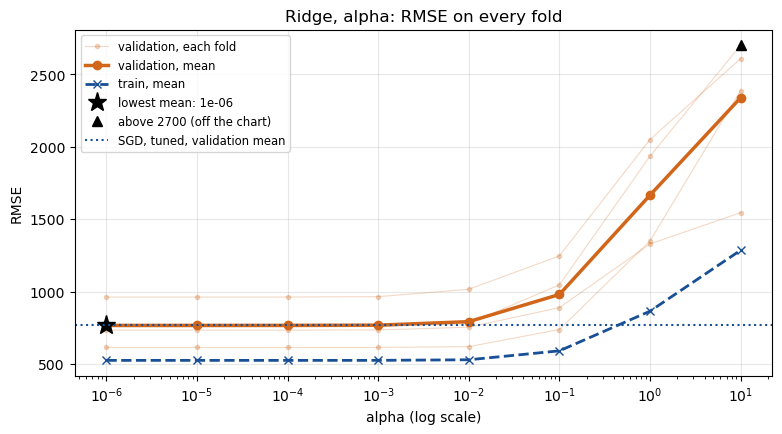

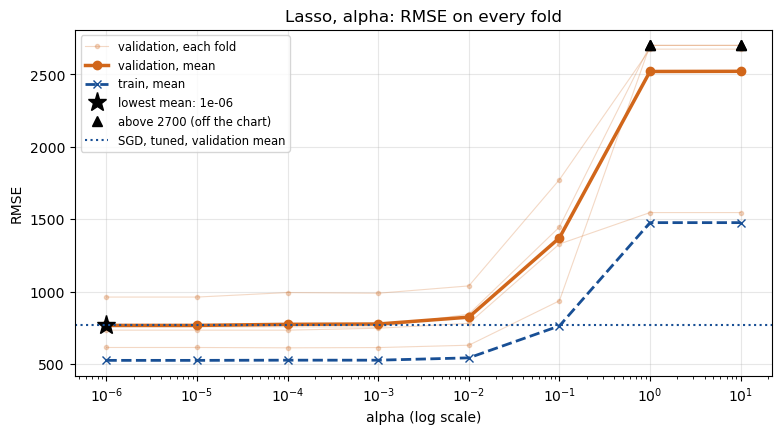

In [37]:
REGULARIZED = []  # every regularized run, the pool the selected model is picked from
for penalty, label in (('l2', 'Ridge'), ('l1', 'Lasso')):
	REGULARIZED += sweep('alpha', ALPHAS, {**SGD_SETTINGS, 'penalty': penalty}, baseline='SGD, tuned', prefix=f'{label}, ', log_x=True).values()

### Notes / Observations

- No penalty helps: every alpha is at or above no penalty, and the cost grows with alpha.
- The "worse" verdicts of the smallest Ridge alphas are changes of 0.2 rentals or less: the change is almost the same on every block, so its SE rounds to 0 and any steady change clears it.
- L1 bites first: at alpha 0.001, Lasso is worse by 9.5 and Ridge by 1.7.
- Strong penalties underfit: training and validation RMSE rise together (Ridge at alpha 10: 1285.5 and 2337.9).
- Lasso from alpha 1 predicts the mean: 2519.8, against Dummy's 2521.6.

## Elastic Net: l1_ratio × alpha

Every pair of the 6 `l1_ratio` values and the 8 `alpha` values. `l1_ratio` 0 would be Ridge and 1 would be Lasso.

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",766.9,525.5,NaN,NaN,,baseline,54
"Elastic Net, l1_ratio=0.1, alpha=1e-06",766.9,525.5,0.0,0.0,1 of 4,worse,54
"Elastic Net, l1_ratio=0.1, alpha=1e-05",766.9,525.5,0.0,0.0,1 of 4,worse,54
"Elastic Net, l1_ratio=0.1, alpha=0.0001",767.1,525.5,0.2,0.1,1 of 4,worse,54
"Elastic Net, l1_ratio=0.1, alpha=0.001",775.7,526.9,8.8,9.6,1 of 4,within noise,49
"Elastic Net, l1_ratio=0.1, alpha=0.01",795.5,530.6,28.6,12.4,0 of 4,worse,51
"Elastic Net, l1_ratio=0.1, alpha=0.1",1031.9,612.4,265.0,66.6,0 of 4,worse,54
"Elastic Net, l1_ratio=0.1, alpha=1",1927.3,1004.5,1160.4,178.3,0 of 4,worse,42
"Elastic Net, l1_ratio=0.1, alpha=10",2519.8,1476.3,1752.9,400.3,0 of 4,worse,38
"Elastic Net, l1_ratio=0.15, alpha=1e-06",766.9,525.5,0.0,0.0,1 of 4,worse,54


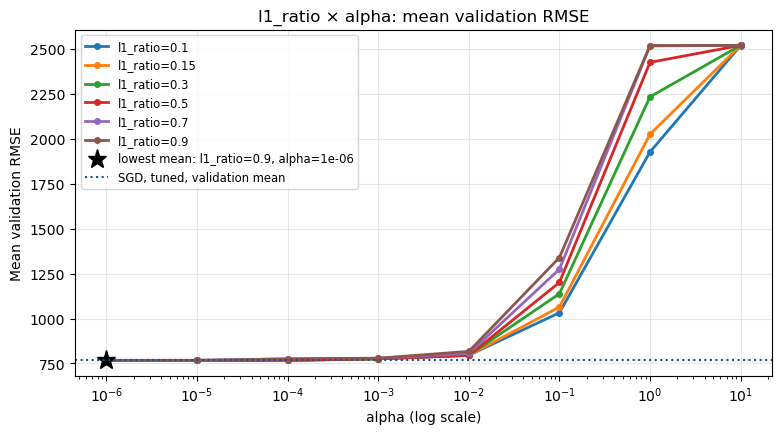

In [38]:
REGULARIZED += cross('l1_ratio', L1_RATIOS, 'alpha', ALPHAS, {**SGD_SETTINGS, 'penalty': 'elasticnet'}, baseline='SGD, tuned', prefix='Elastic Net, ', log_x=True).values()

### Notes / Observations

- Up to alpha 0.00001 the mix does not matter: every pair gives 766.9, the same as no penalty.
- The "worse" verdicts up to alpha 0.0001 (`l1_ratio` 0.1, 0.15 and 0.5) are changes under 1 rental: the same near-zero SE effect as in the Ridge sweep.
- Once the penalty acts, more L1 costs more: at alpha 0.1 the cost grows from +265.0 (`l1_ratio` 0.1) to +572.3 (0.9).
- Strong penalties reach the mean sooner with more L1: at alpha 1, `l1_ratio` 0.9 already predicts the mean (2519.8) while 0.1 is at 1927.3.

## Selected Model

The regularized setting with the lowest mean validation RMSE, against the tuned SGD with no penalty.

In [39]:
SELECTED = min(REGULARIZED, key=lambda name: RUNS[name]['validation rmse'].mean())
display(pd.Series({**SETTINGS[SELECTED], 'degree': DEGREE}, name=SELECTED).astype(str).to_frame())  # as text: the float format would round a small alpha or tol to 0

table([SELECTED], baseline='SGD, tuned')

,"Lasso, alpha=1e-06"
penalty,l1
learning_rate,adaptive
eta0,0.01
power_t,0.25
average,False
max_iter,10000
tol,0.001
random_state,42
alpha,1e-06
degree,3


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",766.9,525.5,NaN,NaN,,baseline,54
"Lasso, alpha=1e-06",766.9,525.5,0.0,0.0,1 of 4,within noise,54


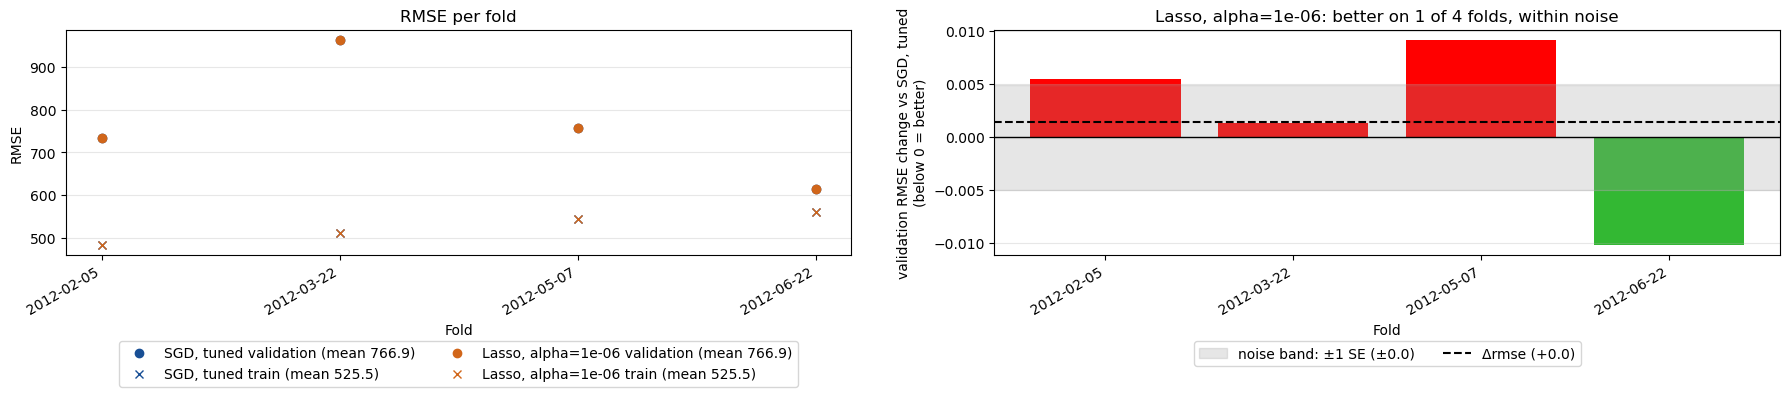

In [40]:
compare('SGD, tuned', SELECTED)

### Notes / Observations

- Selected as required, not because it helps: Lasso at alpha 0.000001, the weakest penalty tried, gives the same 766.9 as no penalty.
- So the regularized pick is no better than tuned SGD, which stays short of the closed form (747.7).

## Train on the Entire Training Set

The selected model refit on all 584 training days and saved. The saved pipeline takes the 11 raw attributes and builds its own columns, at degree 3.

In [41]:
final = build(SGDRegressor(**SETTINGS[SELECTED]), FEATURES, degree=DEGREE, expand=EXPAND).fit(X, y)
Q2_CONSTS.MODEL_OUTPUT_DIR.mkdir(exist_ok=True)
joblib.dump(final, Q2_CONSTS.MODEL_OUTPUT_DIR / 'polynomial_regression.joblib')

pd.Series({
	'training rows': len(X),
	'epochs run': PIPELINES.final_model(final).n_iter_,
	'train rmse': mean_squared_error(y, final.predict(X), squared=False),
}, dtype=object).to_frame(SELECTED)  # object: keeps the counts whole numbers

,"Lasso, alpha=1e-06"
training rows,584
epochs run,43
train rmse,562.8


### Notes / Observations

- The full fit's training RMSE is higher than the folds' (562.8 against 525.5): it also trains on the last validation block, which no fold trains on.

## Training and Validation Loss by Epoch

The hint's `warm_start` loop restarts the learning rate schedule on every `fit` call, so epoch k here is a fresh fit with `max_iter=k` and the same seed, exactly the selected model's first k epochs. Once a fold's fit stops on its own (`tol`), its line stays flat. Shown on the 4 time-ordered folds. Epoch k costs a fresh fit of k epochs, so the epochs are scored on up to 60 points spread evenly on a log scale (rounding to whole epochs merges some of the first ones), up to 10 past the last fold's stop, and drawn on a log scale.

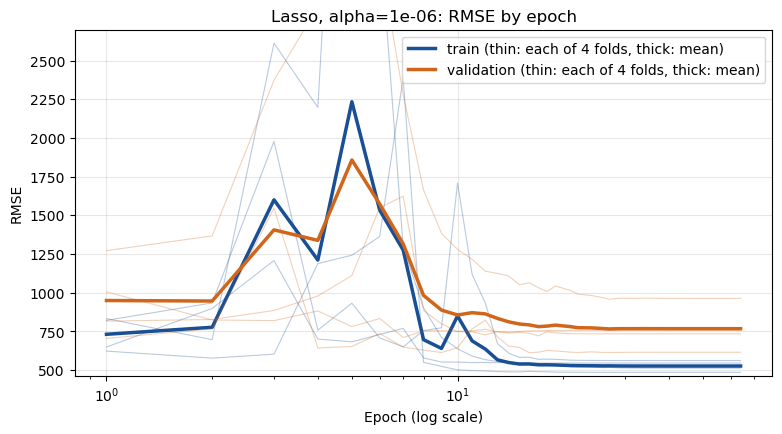

In [42]:
EPOCHS = int(RUNS[SELECTED]['epochs'].max()) + 10  # past the last fold's stop, where every line is flat
EPOCH_GRID = np.unique(np.round(np.geomspace(1, EPOCHS, 60)).astype(int))  # 60 points, evenly spread on a log scale
curve = PIPELINES.epoch_rmse(pipeline=build(SGDRegressor(**SETTINGS[SELECTED]), FEATURES, degree=DEGREE, expand=EXPAND), X=X, y=y, folds=FOLDS, epochs=EPOCH_GRID)
PLOTTING.loss_curve(curve=curve, title=f'{SELECTED}: RMSE by epoch', log_x=True, ymax=YMAX);

### Notes / Observations

- An unstable start: training and validation RMSE jump from epoch 3, peak at epoch 5 (one fold leaves the top of the chart), and settle by about epoch 15. The starting step is too large for some folds; `adaptive` cuts it once their loss stops improving.
- No overfitting with more epochs: validation RMSE is flat from about epoch 20 to the end and never turns back up.
- The gap that remains is the time gap of the Baselines, not overfitting: the validation days come after the training days.

# Overfitting and Underfitting

Validation loss is read three ways in this notebook: by degree (Degree and Expanded Columns with the closed form, Degree × eta0 with SGD), by penalty (Regularization), and by epoch (Stopping Tolerance, and the loss curve above). This section puts the degrees side by side with the selected settings: cross validated on every fold, then loss by epoch at each degree. Overfitting and underfitting are read as in Method. The gap between training and validation days is read against Dummy's (the Time gap bullet in Method), which the table shows.

## By Degree

In [43]:
BY_DEGREE = [f'Selected settings, degree {degree}' for degree in DEGREES]
for degree, name in zip(DEGREES, BY_DEGREE):
	sgd(name, SETTINGS[SELECTED], degree=degree)

table(['Dummy', *BY_DEGREE], baseline=SELECTED)

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"Lasso, alpha=1e-06",766.9,525.5,NaN,NaN,,baseline,54
Dummy,2521.6,1476.3,1754.7,401.2,0 of 4,worse,<NA>
"Selected settings, degree 1",1066.2,680.0,299.3,112.8,0 of 4,worse,50
"Selected settings, degree 2",852.7,587.8,85.8,30.1,0 of 4,worse,50
"Selected settings, degree 3",766.9,525.5,0.0,0.0,0 of 4,within noise,54
"Selected settings, degree 4",398321425.7,267938538.5,398320658.8,438621213.6,0 of 4,within noise,36


### Notes / Observations

- Degree 3 is the best degree that converges: validation RMSE falls from 1066.2 at degree 1 to 766.9 at degree 3, and degrees 1 and 2 are worse on all 4 blocks.
- Degree 4 diverges at the selected step (398321425.7): it reads within noise only because its SE is larger than its change, and it is worse on all 4 blocks. What limits degree 4 here is the step, not overfitting.
- No degree up to 3 overfits beyond the time shift: the gap between training and validation days narrows from degree 1 to degree 3 (degree 3: 525.5 against 766.9).
- Every converging degree's gap stays well below Dummy's (1476.3 against 2521.6).
- `Selected settings, degree 3` is the selected model itself, so its change is 0.0 by definition.

## Loss by Epoch at Each Degree

The selected settings at degrees 1 to 4, on the same folds and epochs as the selected model's curve.

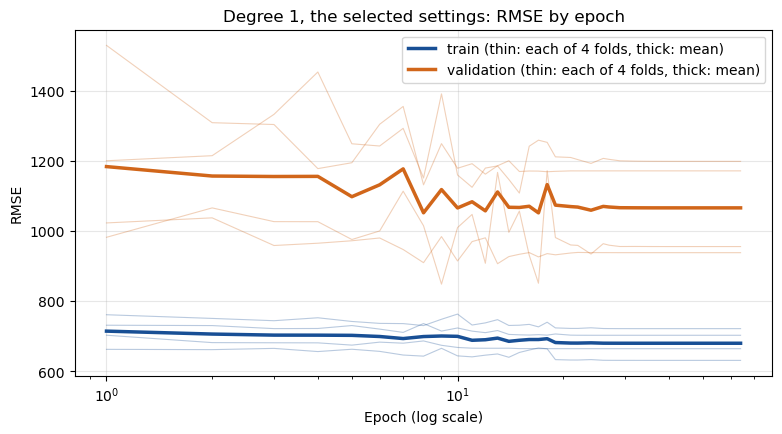

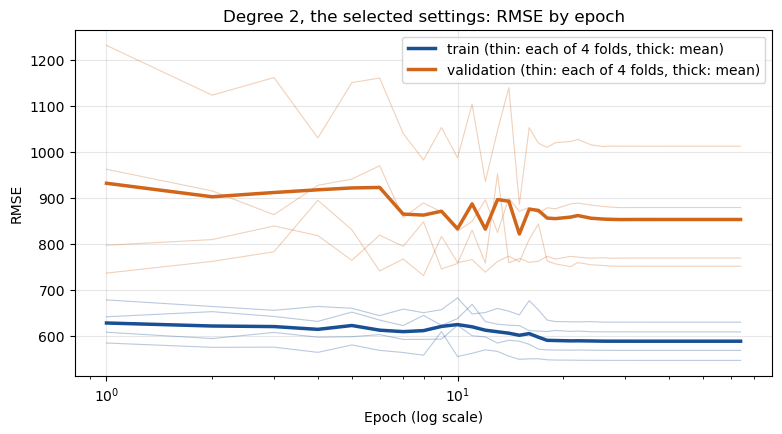

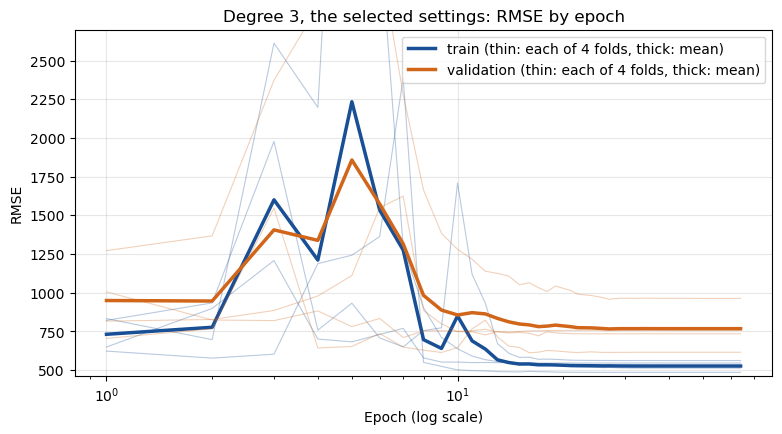

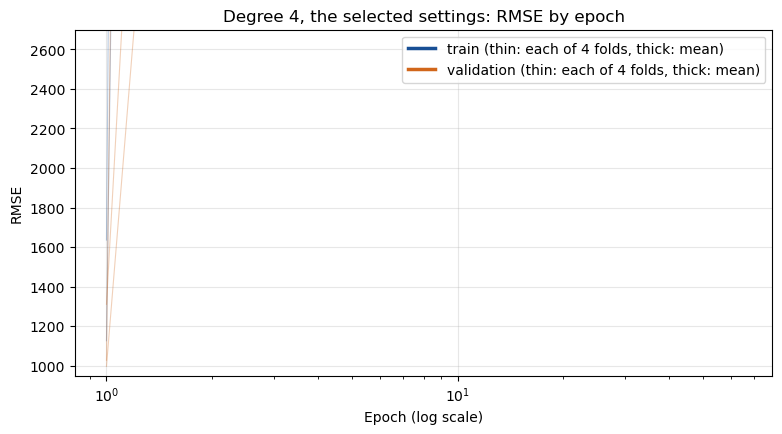

In [44]:
for degree in DEGREES:
	curve = PIPELINES.epoch_rmse(pipeline=build(SGDRegressor(**SETTINGS[SELECTED]), FEATURES, degree=degree, expand=EXPAND), X=X, y=y, folds=FOLDS, epochs=EPOCH_GRID)
	PLOTTING.loss_curve(curve=curve, title=f'Degree {degree}, the selected settings: RMSE by epoch', log_x=True, ymax=YMAX)

### Notes / Observations

- Degrees 1 to 3 settle by about epoch 20 and stay flat: no degree overfits with more epochs.
- Degrees 1 and 2 underfit: their validation curves flatten at a higher RMSE, and the extra epochs do not close the distance to degree 3.
- Degree 4 leaves the top of the chart within the first epochs: the selected step is too large at degree 4, so this curve shows divergence, not overfitting.
- The degree 3 chart is the selected model's curve above.